# TP1 · Task 4: Optimising the selected models, choosing the threshold and the final evaluation
## Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Dataset:** educational version of the *China EV Charging Dataset* (Zhang et al., 2025). It has 441,077 charging sessions,
92 charging posts, 13 stations and 3 districts, from 2020 to 2021.

Task 4 closes the modelling work. We tune the hyperparameters of the most promising models of Task 3, compare each tuned model with
its Task 3 configuration, choose a decision threshold for the final model from validation predictions, check its calibration, and
then evaluate the final model once on the test period that every earlier task left untouched. The notebook ends by looking at which
groups of information the final model relies on.

### How to read this notebook

| # | Section | Requirement of the Task 4 brief |
|---|---------|---------------------------------|
| 1 | Setup and inputs | — |
| 2 | Data, folds and the Task 3 reference | the protocol of Task 2, unchanged, and a check that Task 3 is reproduced |
| 3 | Models chosen for optimisation | two or three promising models, justified |
| 4 | Hyperparameter search | explicit search space, procedure, temporal order, PR-AUC objective, selected configuration |
| 5 | Optimised versus initial, and the final model | is the improvement meaningful and stable? |
| 6 | Decision threshold | one criterion on validation predictions; 0.50 against the selected cut-off; operational consequences |
| 7 | Calibration check | is calibration needed for the chosen use? |
| 8 | Freezing the final choices | model, features and cut-off written to file before the test |
| 9 | Final evaluation on the test period | one evaluation, threshold applied unchanged |
| 10 | Interpretation of the final model | which feature groups and variables drive it, with limitations |
| 11 | Conclusions and limitations | — |
| 12 | Saved files and decision log | — |
| 13 | Final comparison and model description | candidate, baseline and final models in one table; final preprocessing, features, hyperparameters and threshold |

The notebook reads what Tasks 2 and 3 saved: the evaluation protocol (`prepared/task2_protocol.json`), the feature groups
(`prepared/feature_groups.json`), the 27 selected features and the Task 3 configurations (`prepared/task3_results.json`), and the
Task 3 fold metrics (`prepared/task3_fold_metrics.csv`). Sections 1 to 8 use only the development period (April 2020 to September
2021): the test rows are dropped right after the file is read. The test period (from 2021-10-01) is read again only in Section 9,
after the final model, its features and its cut-off have been written to `prepared/task4_frozen.json`.

---
## 1. Setup and inputs

In [1]:
import json
import time
import warnings
from datetime import datetime
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_task4"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}      # every other end cause is abnormal (Task 1, Section 5)

# The evaluation comes from the Task 2 files and the feature set from Task 3, so the three tasks cannot drift apart.
PROTOCOL = json.loads((OUT_DIR / "task2_protocol.json").read_text())
FEATURE_GROUPS = json.loads((OUT_DIR / "feature_groups.json").read_text())
TASK3 = json.loads((OUT_DIR / "task3_results.json").read_text())
BURN_IN_END = pd.Timestamp(PROTOCOL["temporal"]["burn_in_end"])
TEST_START = pd.Timestamp(PROTOCOL["temporal"]["test_start"])
ALERT_BUDGETS = tuple(PROTOCOL["metrics"]["operational"]["alert_budgets"])
GROUPS = FEATURE_GROUPS["groups"]
TOLERANCE = TASK3["tolerance"]                 # practical tolerance of Task 3 (Section 3.3) for small PR-AUC differences
SELECTED = TASK3["selected_features"]          # the 27 features selected by the Task 3 ablation
TARGET_ALERT_RATE = 0.10                       # threshold criterion of Section 6
assert len(SELECTED) == 27 and "post_id" not in SELECTED and "tariff_period" not in SELECTED

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
C_NORMAL, C_ABN, C_GREY, C_ORANGE, C_GREEN, C_PURPLE = "#4C72B0", "#C44E52", "#7F7F7F", "#E1A730", "#2a9d8f", "#8172B3"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a decision together with its evidence (the full log is shown in Section 12)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()


print(f"Task 3 feature set: {len(SELECTED)} features | tolerance {TOLERANCE} | test period from {TEST_START.date()}")

Task 3 feature set: 27 features | tolerance 0.005 | test period from 2021-10-01


---
## 2. Data, folds and the Task 3 reference

We read only the 27 selected features and the three columns that define the target and the fold boundaries (`Start Time`, `End Time`,
`end_cause`). The function below keeps one period right after the start time is parsed, before the target or any feature is built.
Sections 2 to 8 call it for the development period only, so the test rows are counted and dropped at once. Section 9 calls it a second
time for the test period, after the final choices are frozen.

In [2]:
RENAME = {   # same short names as in Tasks 1 to 3
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Start Time": "start_time", "End Time": "end_time", "Temperature(℃)": "temperature",
    "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
INVERSE_RENAME = {short: original for original, short in RENAME.items()}
DERIVED = {"hour": "Start Time", "dow": "Start Time", "rain_flag": "Precipitation(mm)"}     # features built from one column (Task 1, Section 12)


def load_sessions(period):
    """Read the course file and keep one period, right after the start time is parsed and before any label or feature exists.
    "development" = from the end of the burn-in to the test start; "test" = from the test start (Section 9 only)."""
    needed = {DERIVED.get(f, INVERSE_RENAME.get(f, f)) for f in SELECTED} | {"Start Time", "End Time", "end_cause"}
    frame = pd.read_csv(DATA_PATH, usecols=sorted(needed)).rename(columns=RENAME)
    frame["start_time"] = pd.to_datetime(frame["start_time"], format="%Y-%m-%d %H:%M:%S")
    counts = {"file": len(frame), "burn-in": int((frame["start_time"] < BURN_IN_END).sum()),
              "test": int((frame["start_time"] >= TEST_START).sum())}
    if period == "development":
        keep = (frame["start_time"] >= BURN_IN_END) & (frame["start_time"] < TEST_START)
    elif period == "test":
        keep = frame["start_time"] >= TEST_START
    else:
        raise ValueError(period)
    frame = frame[keep].reset_index(drop=True)            # the other period goes here, before any label or feature exists

    for col in ("location", "district", "end_cause"):
        frame[col] = frame[col].str.strip()
    frame["end_time"] = pd.to_datetime(frame["end_time"], format="%Y-%m-%d %H:%M:%S")
    frame["hour"] = frame["start_time"].dt.hour.astype("int8")
    frame["dow"] = frame["start_time"].dt.dayofweek.astype("int8")
    frame["rain_flag"] = (frame["precipitation"] > 0).astype("int8")
    frame[TARGET] = (~frame["end_cause"].isin(NORMAL_CAUSES)).astype("int8")
    return frame, counts


df, counts = load_sessions("development")
print(f"File: {counts['file']:,} sessions | burn-in removed: {counts['burn-in']:,} | test removed: {counts['test']:,}")
print(f"Development data: {len(df):,} sessions ({df['start_time'].min().date()} to {df['start_time'].max().date()}), "
      f"abnormal share {df[TARGET].mean():.2%}")
assert df["start_time"].max() < TEST_START and len(df) == 346_979

File: 441,077 sessions | burn-in removed: 14,017 | test removed: 80,081
Development data: 346,979 sessions (2020-04-01 to 2021-09-30), abnormal share 18.54%


### 2.1 The four temporal folds

The folds are rebuilt from the boundaries stored in the Task 2 protocol, with the same purge rule and the same assertions as in Task 3.
Fold *k* trains on every labelled development session that started and ended before its validation quarter, and validates on that quarter.

In [3]:
def temporal_folds(frame, protocol=PROTOCOL):
    """Expanding-window folds of Task 2: train = sessions that started AND ended before the validation quarter (purge),
    valid = sessions that started inside the quarter."""
    folds = []
    for spec in protocol["temporal"]["folds"]:
        lo, hi = pd.Timestamp(spec["validate_from"]), pd.Timestamp(spec["validate_before"])
        folds.append({"fold": spec["fold"], "lo": lo, "hi": hi,
                      "train": frame.index[(frame["start_time"] < lo) & (frame["end_time"] < lo)],
                      "valid": frame.index[(frame["start_time"] >= lo) & (frame["start_time"] < hi)]})
    return folds


FOLDS = temporal_folds(df)
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    assert tr["start_time"].min() >= BURN_IN_END and tr["end_time"].max() < f["lo"]
    assert va["start_time"].min() >= f["lo"] and va["start_time"].max() < f["hi"]
    assert np.intersect1d(f["train"], f["valid"]).size == 0
for a, b in zip(FOLDS[:-1], FOLDS[1:]):
    assert a["hi"] == b["lo"] and np.isin(a["train"], b["train"]).all()
for f, spec in zip(FOLDS, PROTOCOL["temporal"]["folds"]):
    assert len(f["train"]) == spec["train_sessions"] and len(f["valid"]) == spec["validation_sessions"]      # same folds as Task 2
assert FOLDS[-1]["hi"] == TEST_START
print("The four folds match the Task 2 protocol and pass the temporal integrity checks.")

fold_table = pd.DataFrame([{"fold": f["fold"], "validation quarter": f"{f['lo'].date()} to {(f['hi'] - pd.Timedelta(days=1)).date()}",
                            "train sessions": len(f["train"]), "validation sessions": len(f["valid"]),
                            "validation abnormal share": df.loc[f["valid"], TARGET].mean()} for f in FOLDS]).set_index("fold")
display(fold_table.style.format({"train sessions": "{:,.0f}", "validation sessions": "{:,.0f}", "validation abnormal share": "{:.1%}"}))

The four folds match the Task 2 protocol and pass the temporal integrity checks.


,validation quarter,train sessions,validation sessions,validation abnormal share
fold,,,,
1,2020-10-01 to 2020-12-31,"111,470","60,364",16.8%
2,2021-01-01 to 2021-03-31,"171,832","41,797",15.8%
3,2021-04-01 to 2021-06-30,"213,641","57,542",18.2%
4,2021-07-01 to 2021-09-30,"271,182","75,769",21.1%


### 2.2 Metrics, the cross-validation runner and the operating point

The metric functions and the runner `cv_run` are those of Task 3, so the numbers of the two notebooks are comparable. `cv_run` builds a
fresh pipeline for each fold, fits it on that fold's training rows only and keeps the predictions of the validation quarter, which the
threshold (Section 6) needs. We add one function, `operating_point`, which turns scores into alerts with a fixed cut-off and returns the
measures that the brief asks for: precision, recall, F1, alert rate, and correct, false and missed alerts per 1,000 sessions. When a
cut-off flags no session, precision and F1 are undefined and shown as "—".

In [4]:
def alert_metrics(y, score, budget, rng):
    """Flag the top `budget` share of sessions by score (ties broken at random). Return the operational measures."""
    n = len(y)
    k = int(round(budget * n))
    order = np.lexsort((rng.random(n), -score))          # sort by -score; ties are shuffled
    flagged = np.zeros(n, dtype=bool)
    flagged[order[:k]] = True
    tp = int((y[flagged] == 1).sum())
    return {"alerts per 1,000": 1000 * k / n,
            "correct alerts per 1,000": 1000 * tp / n,
            "false alerts per 1,000": 1000 * (k - tp) / n,
            "missed per 1,000": 1000 * (int(y.sum()) - tp) / n,
            "precision": tp / k, "recall": tp / y.sum()}


def evaluate_scores(y, score, probability=None, rng=None):
    """All Task 2 metrics for one set of predictions. `probability` (optional) is used for Brier score and log-loss."""
    rng = rng or np.random.default_rng(SEED)
    y = np.asarray(y)
    prevalence = y.mean()
    out = {"abnormal share": prevalence, "PR-AUC": average_precision_score(y, score)}
    out["lift"] = out["PR-AUC"] / prevalence
    out["ROC-AUC"] = roc_auc_score(y, score)
    if probability is not None:
        out["Brier"] = brier_score_loss(y, probability)
        out["log-loss"] = log_loss(y, np.clip(probability, 1e-6, 1 - 1e-6))
    for q in ALERT_BUDGETS:
        for name, value in alert_metrics(y, score, q, rng).items():
            out[f"{name} @{q:.0%}"] = value
    return out


def summarise_folds(values, weights):
    """Aggregate one metric over the temporal folds (values and weights are indexed by fold number)."""
    v = pd.Series(values, dtype=float)
    return pd.Series({"mean (unweighted)": v.mean(),
                      "mean (weighted by validation sessions)": np.average(v, weights=weights),
                      "std across folds": v.std(ddof=1),
                      "worst fold": v.min(), "best fold": v.max(),
                      "trend per fold": np.polyfit(np.arange(1, len(v) + 1), v.to_numpy(), 1)[0]})


def paired(model, competitor):
    """Fold-by-fold difference `model - competitor` of one metric (Series indexed by fold) and its summary."""
    diff = pd.Series(model, dtype=float) - pd.Series(competitor, dtype=float)
    summary = {"mean difference": diff.mean(), "std of differences": diff.std(ddof=1), "folds won": f"{int((diff > 0).sum())} of {len(diff)}",
               "smallest difference": diff.min(), "largest difference": diff.max()}
    return diff, pd.Series(summary)


METRICS, PREDS = [], {}       # per-fold metrics and validation predictions of every experiment, keyed by experiment label


def cv_run(label, make_model, features):
    """Run one experiment under the Task 2 protocol: a fresh pipeline per fold, fitted on that fold's training rows only."""
    rows = []
    for f in FOLDS:
        tr, va = df.loc[f["train"]], df.loc[f["valid"]]
        started = time.time()
        model = make_model(features).fit(tr[features], tr[TARGET])
        if isinstance(model.named_steps["clf"], HistGradientBoostingClassifier):
            fitted = model.named_steps["clf"]
            assert not fitted.do_early_stopping_ and fitted.n_iter_ == fitted.max_iter
        p = model.predict_proba(va[features])[:, 1]
        seconds = time.time() - started
        PREDS[(label, f["fold"])] = p
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(va), "seconds": seconds,
                     **evaluate_scores(va[TARGET].to_numpy(), p, p, rng=np.random.default_rng(SEED))})
    result = pd.DataFrame(rows)
    METRICS.append(result)
    return result


def metric_table(labels, metric="PR-AUC"):
    """Fold-by-fold table of one metric for several experiments, with the mean over folds."""
    all_metrics = pd.concat(METRICS)
    t = all_metrics[all_metrics["model"].isin(labels)].pivot(index="model", columns="fold", values=metric).loc[labels]
    t.columns = [f"fold {c}" for c in t.columns]
    t["mean"] = t.mean(axis=1)
    return t


def operating_point(y, score, cut_off):
    """Alerts at a fixed cut-off (a session is flagged if score >= cut_off). Precision and F1 are NaN when nothing is flagged."""
    y, flagged = np.asarray(y), np.asarray(score) >= cut_off
    n, k = len(y), int(flagged.sum())
    tp = int((y[flagged] == 1).sum())
    precision = tp / k if k else np.nan
    recall = tp / y.sum()
    f1 = np.nan if not k else (0.0 if tp == 0 else 2 * precision * recall / (precision + recall))
    return {"cut-off": cut_off, "precision": precision, "recall": recall, "F1": f1, "alert rate": k / n,
            "correct per 1,000": 1000 * tp / n, "false per 1,000": 1000 * (k - tp) / n, "missed per 1,000": 1000 * (int(y.sum()) - tp) / n}


OP_FORMAT = {"cut-off": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "alert rate": "{:.1%}",
             "correct per 1,000": "{:.1f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}

### 2.3 Baselines and the Task 3 configurations

B0 (random scores, with the training prior as probability) and B1 (the 7-day failure rate of the post) are computed again with the Task 3
definitions. We then rerun the three Task 3 configurations that Section 3 selects for optimisation and check that every fold gives the
PR-AUC saved by Task 3. If both notebooks agree to the third decimal, any later difference comes from the hyperparameters and not from
the code or the environment.

In [5]:
rng = np.random.default_rng(SEED)
rows = []
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    y = va[TARGET].to_numpy()
    prior = tr[TARGET].mean()                                            # learned inside the training fold
    s_b1 = va["post_previous_abnormal_rate_7D"].to_numpy()
    for label, score, prob in [("B0 no skill", rng.random(len(y)), np.full(len(y), prior)), ("B1 post failure rate (7 days)", s_b1, s_b1)]:
        PREDS[(label, f["fold"])] = score
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(y), **evaluate_scores(y, score, prob, rng=rng)})
METRICS.append(pd.DataFrame(rows))
BASELINES = ["B0 no skill", "B1 post failure rate (7 days)"]
b = metric_table(BASELINES)
display(b.style.format("{:.3f}"))
print(f"B0 mean PR-AUC = {b.loc[BASELINES[0], 'mean']:.3f}, B1 mean PR-AUC = {b.loc[BASELINES[1], 'mean']:.3f} (Task 3 reported 0.181 and 0.511)")
assert abs(b.loc[BASELINES[0], "mean"] - 0.181) < 0.001 and abs(b.loc[BASELINES[1], "mean"] - 0.511) < 0.001

,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
B0 no skill,0.172,0.162,0.181,0.210,0.181
B1 post failure rate (7 days),0.499,0.456,0.547,0.540,0.511


B0 mean PR-AUC = 0.181, B1 mean PR-AUC = 0.511 (Task 3 reported 0.181 and 0.511)


In [6]:
def tree_view(features):
    """Preprocessing of tree-based models (Task 1, Section 13): ordinal codes for the categories (unseen category -> -1, treated as missing),
    everything else untouched, and missing values kept as NaN."""
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    rest = [c for c in features if c not in cat]
    steps = [("num", "passthrough", rest)]
    if cat:
        steps.insert(0, ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float), cat))
    return ColumnTransformer(steps, verbose_feature_names_out=False).set_output(transform="pandas")


# Each factory returns (label, factory, hyperparameters). The label lists every value, so a configuration is never ambiguous.
def make_boosting(max_depth, learning_rate, max_iter, min_samples_leaf):
    params = {"max_depth": max_depth, "learning_rate": learning_rate, "max_iter": max_iter, "min_samples_leaf": min_samples_leaf}

    def factory(features):
        cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
        return Pipeline([("prep", tree_view(features)),
                         ("clf", HistGradientBoostingClassifier(**params, categorical_features=cat or None, early_stopping=False, random_state=SEED))])
    return f"HGB depth={max_depth}, lr={learning_rate}, {max_iter} it, leaf={min_samples_leaf}", factory, params


def make_forest(min_samples_leaf, max_features):
    params = {"min_samples_leaf": min_samples_leaf, "max_features": max_features}

    def factory(features):
        return Pipeline([("prep", tree_view(features)),
                         ("clf", RandomForestClassifier(n_estimators=200, **params, n_jobs=-1, random_state=SEED))])
    return f"RF leaf={min_samples_leaf}, features={max_features}", factory, params


def make_tree(max_depth, min_samples_leaf, criterion):
    params = {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf, "criterion": criterion}

    def factory(features):
        return Pipeline([("prep", tree_view(features)), ("clf", DecisionTreeClassifier(**params, random_state=SEED))])
    return f"DT depth={max_depth}, leaf={min_samples_leaf}, {criterion}", factory, params


MAKERS = {"Gradient boosting": make_boosting, "Random forest": make_forest, "Decision tree": make_tree}


def select_simplest(labels):
    """Highest mean PR-AUC; if a simpler configuration (earlier in `labels`) is within TOLERANCE of it, keep the simplest such one."""
    means = metric_table(labels)["mean"]
    best = means.max()
    return next(label for label in labels if means[label] >= best - TOLERANCE)


def config_table(labels, chosen):
    """Per-fold PR-AUC and the mean of the other metrics for a grid of configurations, with the chosen one marked."""
    t = metric_table(labels)
    all_metrics = pd.concat(METRICS)
    other = all_metrics[all_metrics["model"].isin(labels)].groupby("model")[["ROC-AUC", "Brier", "log-loss"]].mean().loc[labels]
    t = t.join(other)
    t["chosen"] = ["yes" if label == chosen else "" for label in labels]
    return t

In [7]:
# The Task 3 configurations, written with the Task 4 factories (Task 3 fixed 100 sessions per leaf for boosting and the tree,
# and sqrt(27) = 5 features per split for the forest).
INITIAL_PARAMS = {"Gradient boosting": dict(max_depth=6, learning_rate=0.1, max_iter=200, min_samples_leaf=100),
                  "Random forest": dict(min_samples_leaf=50, max_features="sqrt"),
                  "Decision tree": dict(max_depth=8, min_samples_leaf=100, criterion="gini")}
TASK3_LABELS = {"Gradient boosting": "HGB depth=6, lr=0.1, 200 it", "Random forest": "RF leaf=50", "Decision tree": "DT depth=8"}
assert all(TASK3["selected_configurations"][name] == label for name, label in TASK3_LABELS.items())

task3_folds = pd.read_csv(OUT_DIR / "task3_fold_metrics.csv")
INITIAL, FACTORY, PARAMS = {}, {}, {}
rows = []
t0 = time.time()
for name, params in INITIAL_PARAMS.items():
    label, factory, params = MAKERS[name](**params)
    INITIAL[name], FACTORY[label], PARAMS[label] = label, factory, params
    mine = cv_run(label, factory, SELECTED).set_index("fold")["PR-AUC"]
    theirs = task3_folds[task3_folds["model"] == TASK3_LABELS[name]].set_index("fold")["PR-AUC"]
    for fold in mine.index:
        rows.append({"model": name, "configuration": label, "fold": fold, "Task 3 PR-AUC": theirs[fold], "Task 4 PR-AUC": mine[fold],
                     "difference": mine[fold] - theirs[fold]})
reproduction = pd.DataFrame(rows)
print(f"three Task 3 configurations x four folds fitted in {time.time() - t0:.0f} s")
display(reproduction.pivot(index="model", columns="fold", values="Task 4 PR-AUC").rename(columns=lambda c: f"fold {c}").style.format("{:.4f}"))
print(f"largest absolute difference from the Task 3 file: {reproduction['difference'].abs().max():.6f}")
assert (reproduction["difference"].abs() < 0.001).all()

three Task 3 configurations x four folds fitted in 72 s


fold,fold 1,fold 2,fold 3,fold 4
model,,,,
Decision tree,0.5865,0.5440,0.6239,0.6352
Gradient boosting,0.6176,0.5755,0.6497,0.6604
Random forest,0.6154,0.5666,0.6460,0.6619


largest absolute difference from the Task 3 file: 0.000000


The four folds are the ones of the Task 2 protocol: 111,470 to 271,182 training sessions and validation quarters with an abnormal share
between 15.8% and 21.1%. The two baselines give the same mean PR-AUC as in Task 3, 0.181 for B0 and 0.511 for B1, fold by fold.

The three Task 3 configurations that we optimise give back the PR-AUC saved by Task 3 in every fold. The largest absolute difference is
0.0001, well below the third decimal and far below the tolerance of 0.005. The code and the environment therefore reproduce Task 3, and any
difference in the searches below comes from the hyperparameters.

---
## 3. Models chosen for optimisation

The brief asks us to optimise two or three of the most promising models. The table below repeats the Task 3 comparison of the six models
(unweighted mean PR-AUC over the four folds, its standard deviation and worst fold, and the fitting time per fold).

In [8]:
CHOICE = {"Gradient boosting": ("boosting", "best mean PR-AUC of Task 3 and cheap to refit"),
          "Random forest": ("bagging with random feature subsets", "0.003 behind boosting, inside the tolerance, from a different ensemble principle"),
          "Decision tree": ("single tree", "best individual model; its complexity controls are the ones MINDD-05 says to choose on validation data")}
rows = []
for record in TASK3["comparison"]:
    name = record["model"].split(" (")[0]
    if name.startswith("B"):
        continue
    rows.append({"model": record["model"], "PR-AUC mean": record["PR-AUC mean"], "std": record["std"], "worst fold": record["worst fold"],
                 "ROC-AUC": record["ROC-AUC"], "Brier": record["Brier"], "seconds per fold": record["seconds per fold"],
                 "chosen for optimisation": "yes" if name in CHOICE else ""})
choice_table = pd.DataFrame(rows).set_index("model")
display(choice_table.style.format({"PR-AUC mean": "{:.3f}", "std": "{:.3f}", "worst fold": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}",
                                   "seconds per fold": "{:.1f}"}))

SELECTED_MODELS = [{"name": name, "principle": principle, "initial_configuration": INITIAL[name],
                    "reason": f"Task 3 mean PR-AUC {choice_table.loc[f'{name} ({TASK3_LABELS[name]})', 'PR-AUC mean']:.3f}; {reason}"}
                   for name, (principle, reason) in CHOICE.items()]
display(pd.DataFrame(SELECTED_MODELS).set_index("name"))

,PR-AUC mean,std,worst fold,ROC-AUC,Brier,seconds per fold,chosen for optimisation
model,,,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.626,0.038,0.575,0.836,0.102,3.2,yes
Random forest (RF leaf=50),0.622,0.042,0.567,0.835,0.102,12.6,yes
Stacking (LR + NB + DT),0.610,0.041,0.556,0.831,0.104,14.1,
Decision tree (DT depth=8),0.597,0.041,0.544,0.824,0.105,2.5,yes
Logistic regression (LR C=0.01),0.593,0.042,0.534,0.825,0.106,2.1,
Naive Bayes (NB),0.525,0.037,0.472,0.814,0.172,0.7,


,principle,initial_configuration,reason
name,,,
Gradient boosting,boosting,"HGB depth=6, lr=0.1, 200 it, leaf=100",Task 3 mean PR-AUC 0.626; best mean PR-AUC of Task 3 and cheap to refit
Random forest,bagging with random feature subsets,"RF leaf=50, features=sqrt","Task 3 mean PR-AUC 0.622; 0.003 behind boosting, inside the tolerance, from a different ensemble principle"
Decision tree,single tree,"DT depth=8, leaf=100, gini",Task 3 mean PR-AUC 0.597; best individual model; its complexity controls are the ones MINDD-05 says to choose on validation data


We optimise gradient boosting, the random forest and the decision tree. They are the two best ensembles and the best individual model of
Task 3, and they represent three different principles: boosting (shallow trees added one after another, each fitted to the errors of the
previous ones), bagging with random feature subsets (many deep trees averaged), and a single tree. Gradient boosting and the forest are only
0.003 apart in mean PR-AUC, inside our tolerance of 0.005, so Task 3 could not separate them and both deserve a search before we name the
final model. The tree is cheap to fit, can be read as rules, and its two complexity controls, the maximum depth and the minimum number of
sessions per leaf, are exactly the settings that the predictive-models slides (MINDD-05) say should be chosen with validation performance.

We leave out the other three models. Stacking (0.610) is 0.015 behind gradient boosting, and tuning it would mean tuning three base models
and a meta-model inside the time-ordered inner loop that Task 3 built, a large cost for a small expected gain. For logistic regression,
Task 3 found that `C = 0.01` and `C = 1` give the same PR-AUC in every fold, so its search space has nothing left to find. Naive Bayes has
only its smoothing to tune, which does not touch the independence assumption that causes its gap.

In [9]:
log_decision("3", "Models chosen for optimisation",
             "Gradient boosting, random forest and decision tree (boosting, bagging with random features, single tree). Stacking, logistic regression and Naive Bayes are not searched.",
             "Task 3 mean PR-AUC 0.626, 0.622 and 0.597; boosting and the forest differ by 0.003 (inside the tolerance); the tree is the best individual model. "
             "Stacking is 0.015 behind boosting; LR gave the same PR-AUC for C = 0.01 and C = 1; NB smoothing does not address its independence assumption.")

---
## 4. Hyperparameter search

### 4.1 Search procedure

We use an exhaustive search over a small, explicit grid for each model. Every configuration goes through `cv_run`: on each of the four
development folds it is fitted on the training window only and scored on the validation quarter that follows, so the search respects time
order and never sees the test period. The objective is the unweighted mean PR-AUC over the four folds, the primary metric of the protocol.
No configuration uses random splits or internal early stopping.

The grids are listed from the simplest to the most complex configuration, and the selection rule is the one that chose every Task 3
configuration: we take the highest mean PR-AUC and keep the simplest configuration within 0.005 of it. The "initial" (Task 3) and the
"optimised" configurations are therefore chosen in the same way. If the chosen value of a hyperparameter lies on the edge of its range,
we widen the range once in that direction and run the new values with the chosen values of the other hyperparameters.

Grid search is not in the slides. We use it because it is the plainest way to state the search space and the procedure, which is what the
brief asks to report, and with at most 40 configurations per model a random search would not cover the space any better. We do not nest the
search inside another cross-validation, because the untouched test period already plays the outer role. Picking the best of many
configurations on the same four folds makes the winning development score slightly optimistic; the single test evaluation of Section 9
is the unbiased check.

| Model | Hyperparameter | Values | Reason for the range |
|-------|----------------|--------|----------------------|
| Gradient boosting | maximum depth | 4, 6, 8 | Task 3 tried 3 and 6; interactions between the post and user histories may need deeper trees |
| | learning rate | 0.05, 0.1 | the two rates of Task 3; a smaller step needs more iterations |
| | iterations | 200, 400 | paired with the rate; a fixed count, no early stopping (Task 3 decision) |
| | minimum sessions per leaf | 50, 100, 200 | Task 3 fixed it at 100; it limits how small a leaf can be on 111k to 271k training sessions |
| Random forest | minimum sessions per leaf | 10, 20, 50, 100 | Task 3 tried 50 and 200 and the smaller value won, so the range moves down |
| | features tried per split | √27 = 5, 9, 13 (a third and a half of the 27) | the number of candidate features controls how different the trees are |
| | number of trees | 200, fixed | more trees only reduce variance; 200 keeps the cost bounded |
| Decision tree | maximum depth | 6, 8, 10, 12, 16 | Task 3 tried 4 to 12 and chose 8 |
| | minimum sessions per leaf | 50, 100, 200, 400 | Task 3 fixed it at 100; the second complexity control of MINDD-05 |
| | split criterion | Gini, entropy | the two impurity measures of the slides |

The simplicity order is: for boosting, fewer iterations, then a shallower tree, then a larger leaf, then a larger learning rate; for the
forest, a larger leaf, then fewer features per split; for the tree, a shallower tree, then a larger leaf, then Gini. Class weights and
resampling stay out, as decided in Task 1 (Section 14): they keep the ranking and distort the probabilities, and the threshold of Section 6
deals with the imbalance at decision time.

In [10]:
GRID_VALUES = {"Gradient boosting": {"max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1], "max_iter": [200, 400], "min_samples_leaf": [50, 100, 200]},
               "Random forest": {"min_samples_leaf": [10, 20, 50, 100], "max_features": ["sqrt", 9, 13]},
               "Decision tree": {"max_depth": [6, 8, 10, 12, 16], "min_samples_leaf": [50, 100, 200, 400], "criterion": ["gini", "entropy"]}}


def n_split_features(value, n=len(SELECTED)):
    """Number of features tried per split ("sqrt" of the 27 features = 5)."""
    return max(1, int(np.sqrt(n))) if value == "sqrt" else value


# Simplicity order used by the tie rule: the simplest configuration sorts first.
ORDER = {"Gradient boosting": ["max_iter", "max_depth", "min_samples_leaf (larger first)", "learning_rate (larger first)"],
         "Random forest": ["min_samples_leaf (larger first)", "max_features"],
         "Decision tree": ["max_depth", "min_samples_leaf (larger first)", "criterion (gini first)"]}
SORT_KEY = {"Gradient boosting": lambda p: (p["max_iter"], p["max_depth"], -p["min_samples_leaf"], -p["learning_rate"]),
            "Random forest": lambda p: (-p["min_samples_leaf"], n_split_features(p["max_features"])),
            "Decision tree": lambda p: (p["max_depth"], -p["min_samples_leaf"], p["criterion"] != "gini")}


def build_grid(name, values):
    """All combinations of the values, as (label, factory, params), sorted from the simplest to the most complex."""
    combos = [dict(zip(values, combo)) for combo in product(*values.values())]
    configs = [MAKERS[name](**params) for params in sorted(combos, key=SORT_KEY[name])]
    for label, factory, params in configs:
        FACTORY[label], PARAMS[label] = factory, params
    return configs


SEARCH = {name: build_grid(name, values) for name, values in GRID_VALUES.items()}
print({name: len(configs) for name, configs in SEARCH.items()})
assert [len(SEARCH[name]) for name in GRID_VALUES] == [36, 12, 40]
assert all(INITIAL[name] in [label for label, _, _ in SEARCH[name]] for name in SEARCH)

log_decision("4", "Search procedure",
             "Exhaustive grid per model (36, 12 and 40 configurations) on the four development folds; objective = unweighted mean PR-AUC; "
             "simplest configuration within 0.005 of the best; a range is widened once if the choice lies on its edge.",
             "Same folds, runner and selection rule as Task 3, so initial and optimised configurations are chosen the same way; "
             "no random split and no early stopping; the test period plays the outer role of a nested search.")

{'Gradient boosting': 36, 'Random forest': 12, 'Decision tree': 40}


In [11]:
# Value added beyond each edge of a range (low edge, high edge). The learning rate is not extended because it is paired with the
# number of iterations, and the split criterion has only the two values of the slides.
EDGE_VALUES = {"Gradient boosting": {"max_depth": (3, 10), "min_samples_leaf": (25, 400), "max_iter": (100, 800)},
               "Random forest": {"min_samples_leaf": (5, 200), "max_features": (3, 20)},
               "Decision tree": {"max_depth": (4, 24), "min_samples_leaf": (25, 800)}}
CHOSEN, EXTENDED, STILL_ON_EDGE, SEARCH_SECONDS = {}, {}, {}, {}


def done_labels():
    return set(pd.concat(METRICS)["model"])


def search_table(name, chosen):
    """Search results of one model: per-fold PR-AUC, mean, std, worst fold, rank, other metrics and cost."""
    labels = [label for label, _, _ in SEARCH[name]]
    t = config_table(labels, chosen)
    folds = [c for c in t.columns if c.startswith("fold")]
    t.insert(len(folds) + 1, "std", t[folds].std(axis=1, ddof=1))
    t.insert(len(folds) + 2, "worst fold", t[folds].min(axis=1))
    t.insert(len(folds) + 3, "rank", t["mean"].rank(ascending=False, method="min").astype(int))
    all_metrics = pd.concat(METRICS)
    t["seconds per fold"] = all_metrics[all_metrics["model"].isin(labels)].groupby("model")["seconds"].mean().loc[labels]
    t["initial"] = ["yes" if label == INITIAL[name] else "" for label in labels]
    return t


def run_search(name):
    """Run every configuration of the grid that has not been run yet and apply the selection rule."""
    started = time.time()
    for label, factory, _ in SEARCH[name]:
        if label not in done_labels():
            cv_run(label, factory, SELECTED)
    SEARCH_SECONDS[name] = time.time() - started
    CHOSEN[name] = select_simplest([label for label, _, _ in SEARCH[name]])
    return CHOSEN[name]


def extend_if_on_edge(name):
    """If a chosen value lies on the edge of its range, add one value beyond it (with the other values fixed at the chosen ones),
    run the new configurations once and select again. Returns the added values, or None if the rule did not fire."""
    chosen = PARAMS[CHOSEN[name]]
    added = {}
    for param, (low, high) in EDGE_VALUES[name].items():
        values = GRID_VALUES[name][param]
        key = n_split_features if param == "max_features" else (lambda v: v)
        ordered = sorted(values, key=key)
        if chosen[param] == ordered[0]:
            added[param] = [low]
        elif chosen[param] == ordered[-1]:
            added[param] = [high]
    if not added:
        EXTENDED[name] = None
        return None
    started = time.time()
    for param, (value,) in added.items():
        label, factory, params = MAKERS[name](**{**chosen, param: value})
        FACTORY[label], PARAMS[label] = factory, params
        if label not in [l for l, _, _ in SEARCH[name]]:
            SEARCH[name].append((label, factory, params))
        if label not in done_labels():
            cv_run(label, factory, SELECTED)
    SEARCH[name].sort(key=lambda config: SORT_KEY[name](config[2]))
    SEARCH_SECONDS[name] += time.time() - started
    CHOSEN[name] = select_simplest([label for label, _, _ in SEARCH[name]])
    EXTENDED[name] = added
    new = PARAMS[CHOSEN[name]]
    STILL_ON_EDGE[name] = [param for param, (value,) in added.items() if new[param] == value]
    return added


SEARCH_FORMAT = {"fold 1": "{:.3f}", "fold 2": "{:.3f}", "fold 3": "{:.3f}", "fold 4": "{:.3f}", "mean": "{:.4f}", "std": "{:.3f}",
                 "worst fold": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.4f}", "log-loss": "{:.4f}", "seconds per fold": "{:.1f}"}


def report_search(name):
    """Run the search of one model, apply the edge rule and show the results."""
    run_search(name)
    first_choice = CHOSEN[name]
    added = extend_if_on_edge(name)
    t = search_table(name, CHOSEN[name])
    print(f"{name}: {len(SEARCH[name])} configurations x 4 folds in {SEARCH_SECONDS[name] / 60:.1f} min")
    if added:
        print(f"  first choice {first_choice} was on the edge of {list(added)}; added {added}")
        if STILL_ON_EDGE[name]:
            print(f"  the choice is still on the new edge for {STILL_ON_EDGE[name]} (reported as a limitation)")
    else:
        print("  no chosen value on the edge of its range; the grid was not extended")
    best = t["mean"].idxmax()
    print(f"  best mean: {best} ({t.loc[best, 'mean']:.4f}) | chosen by the rule: {CHOSEN[name]} ({t.loc[CHOSEN[name], 'mean']:.4f}) | "
          f"initial: {INITIAL[name]} ({t.loc[INITIAL[name], 'mean']:.4f}, rank {t.loc[INITIAL[name], 'rank']})")
    shown = t.sort_values("mean", ascending=False).head(10)
    if INITIAL[name] not in shown.index:
        shown = pd.concat([shown, t.loc[[INITIAL[name]]]])
    display(shown.style.format(SEARCH_FORMAT))
    return t

### 4.2 Gradient boosting

In [12]:
search_boosting = report_search("Gradient boosting")
c = search_boosting.loc[CHOSEN["Gradient boosting"]]
log_decision("4", "Gradient boosting configuration", f"{CHOSEN['Gradient boosting']}.",
             f"Mean PR-AUC {c['mean']:.4f}, worst fold {c['worst fold']:.3f}, rank {c['rank']} of {len(search_boosting)}; "
             f"edge rule: {EXTENDED['Gradient boosting'] or 'did not fire'}.")

Gradient boosting: 39 configurations x 4 folds in 10.4 min
  first choice HGB depth=4, lr=0.1, 200 it, leaf=200 was on the edge of ['max_depth', 'min_samples_leaf', 'max_iter']; added {'max_depth': [3], 'min_samples_leaf': [400], 'max_iter': [100]}
  the choice is still on the new edge for ['max_iter'] (reported as a limitation)
  best mean: HGB depth=6, lr=0.05, 400 it, leaf=200 (0.6273) | chosen by the rule: HGB depth=4, lr=0.1, 100 it, leaf=200 (0.6235) | initial: HGB depth=6, lr=0.1, 200 it, leaf=100 (0.6258, rank 12)


,fold 1,fold 2,fold 3,fold 4,mean,std,worst fold,rank,ROC-AUC,Brier,log-loss,chosen,seconds per fold,initial
model,,,,,,,,,,,,,,
"HGB depth=6, lr=0.05, 400 it, leaf=200",0.619,0.576,0.650,0.663,0.6273,0.039,0.576,1,0.836,0.1017,0.3365,,5.2,
"HGB depth=6, lr=0.05, 200 it, leaf=200",0.621,0.575,0.650,0.663,0.6272,0.039,0.575,2,0.837,0.1017,0.3363,,3.5,
"HGB depth=6, lr=0.05, 200 it, leaf=100",0.620,0.575,0.650,0.662,0.6271,0.039,0.575,3,0.837,0.1018,0.3365,,3.0,
"HGB depth=8, lr=0.05, 200 it, leaf=200",0.621,0.575,0.650,0.662,0.6270,0.039,0.575,4,0.837,0.1018,0.3365,,3.4,
"HGB depth=8, lr=0.05, 400 it, leaf=200",0.619,0.576,0.650,0.662,0.6269,0.039,0.576,5,0.836,0.1018,0.3368,,6.7,
"HGB depth=8, lr=0.05, 200 it, leaf=100",0.622,0.574,0.650,0.661,0.6268,0.039,0.574,6,0.837,0.1018,0.3366,,2.9,
"HGB depth=6, lr=0.05, 400 it, leaf=100",0.619,0.576,0.651,0.660,0.6265,0.038,0.576,7,0.836,0.1019,0.3370,,5.3,
"HGB depth=6, lr=0.1, 200 it, leaf=200",0.618,0.575,0.650,0.662,0.6263,0.039,0.575,8,0.836,0.1019,0.3371,,3.2,
"HGB depth=8, lr=0.05, 400 it, leaf=100",0.619,0.575,0.651,0.661,0.6262,0.039,0.575,9,0.836,0.1019,0.3370,,5.6,


The search tried 39 configurations in 10.3 minutes: the 36 of the grid and 3 more from the edge rule. The first choice of the rule (depth 4,
rate 0.1, 200 iterations, leaves of at least 200 sessions) sat on the edge of three ranges, so we added a depth of 3, leaves of 400 and 100
iterations. The new choice is depth 4, rate 0.1, 100 iterations and leaves of 200, with a mean PR-AUC of 0.6235. It is still on the edge for
the number of iterations, which we report as a limitation rather than widening a second time.

The surface is flat. The best configuration (depth 6, rate 0.05, 400 iterations, leaves of 200) reaches 0.6273, and the Task 3 configuration
is 12th with 0.6258, only 0.0015 below it. The ten best configurations differ by less than 0.002. A smaller learning rate helps a little,
but by less than the tolerance, so the rule moves to the simplest configuration inside the band and not to the best one.

### 4.3 Random forest

In [13]:
search_forest = report_search("Random forest")
c = search_forest.loc[CHOSEN["Random forest"]]
log_decision("4", "Random forest configuration", f"{CHOSEN['Random forest']}.",
             f"Mean PR-AUC {c['mean']:.4f}, worst fold {c['worst fold']:.3f}, rank {c['rank']} of {len(search_forest)}; "
             f"edge rule: {EXTENDED['Random forest'] or 'did not fire'}.")

Random forest: 13 configurations x 4 folds in 16.8 min
  first choice RF leaf=100, features=9 was on the edge of ['min_samples_leaf']; added {'min_samples_leaf': [200]}
  best mean: RF leaf=50, features=13 (0.6255) | chosen by the rule: RF leaf=100, features=9 (0.6234) | initial: RF leaf=50, features=sqrt (0.6224, rank 11)


,fold 1,fold 2,fold 3,fold 4,mean,std,worst fold,rank,ROC-AUC,Brier,log-loss,chosen,seconds per fold,initial
model,,,,,,,,,,,,,,
"RF leaf=50, features=13",0.618,0.572,0.648,0.664,0.6255,0.040,0.572,1,0.835,0.1020,0.3378,,26.5,
"RF leaf=20, features=13",0.618,0.572,0.648,0.664,0.6254,0.040,0.572,2,0.833,0.1021,0.3385,,29.0,
"RF leaf=20, features=9",0.618,0.572,0.648,0.664,0.6254,0.041,0.572,3,0.834,0.1021,0.3384,,20.8,
"RF leaf=50, features=9",0.618,0.571,0.648,0.663,0.6252,0.041,0.571,4,0.835,0.1021,0.3379,,20.0,
"RF leaf=20, features=sqrt",0.616,0.570,0.648,0.663,0.6244,0.041,0.570,5,0.834,0.1022,0.3387,,13.2,
"RF leaf=10, features=9",0.615,0.572,0.647,0.663,0.6243,0.040,0.572,6,0.832,0.1024,0.3399,,22.3,
"RF leaf=100, features=13",0.617,0.570,0.647,0.662,0.6242,0.041,0.570,7,0.835,0.1022,0.3380,,26.2,
"RF leaf=10, features=sqrt",0.616,0.569,0.647,0.663,0.6240,0.041,0.569,8,0.833,0.1024,0.3397,,13.5,
"RF leaf=10, features=13",0.615,0.571,0.647,0.663,0.6239,0.041,0.571,9,0.831,0.1024,0.3402,,31.1,


The forest search tried 13 configurations in 17.1 minutes, the slowest of the three searches because each configuration fits 200 deep trees
on each fold. The first choice (leaves of 100 sessions, 9 features per split) was on the largest leaf size, so we added leaves of 200; the
choice did not move. The best configuration (leaves of 50, 13 features per split) reaches 0.6255, the chosen one 0.6234 and the Task 3
configuration 0.6224, 11th of 13. Eleven of the 13 configurations lie within 0.0031 of the best. Trying more features per split helps
slightly, but the gain stays inside the tolerance.

### 4.4 Decision tree

In [14]:
search_tree = report_search("Decision tree")
c = search_tree.loc[CHOSEN["Decision tree"]]
log_decision("4", "Decision tree configuration", f"{CHOSEN['Decision tree']}.",
             f"Mean PR-AUC {c['mean']:.4f}, worst fold {c['worst fold']:.3f}, rank {c['rank']} of {len(search_tree)}; "
             f"edge rule: {EXTENDED['Decision tree'] or 'did not fire'}.")

Decision tree: 41 configurations x 4 folds in 8.3 min
  first choice DT depth=8, leaf=400, entropy was on the edge of ['min_samples_leaf']; added {'min_samples_leaf': [800]}
  best mean: DT depth=16, leaf=400, entropy (0.6035) | chosen by the rule: DT depth=8, leaf=400, entropy (0.5994) | initial: DT depth=8, leaf=100, gini (0.5974, rank 20)


,fold 1,fold 2,fold 3,fold 4,mean,std,worst fold,rank,ROC-AUC,Brier,log-loss,chosen,seconds per fold,initial
model,,,,,,,,,,,,,,
"DT depth=16, leaf=400, entropy",0.596,0.547,0.629,0.642,0.6035,0.042,0.547,1,0.824,0.1048,0.3499,,3.5,
"DT depth=16, leaf=400, gini",0.596,0.548,0.630,0.640,0.6035,0.042,0.548,2,0.824,0.1048,0.3508,,3.4,
"DT depth=12, leaf=400, entropy",0.595,0.547,0.630,0.642,0.6033,0.043,0.547,3,0.825,0.1047,0.3487,,3.3,
"DT depth=12, leaf=400, gini",0.596,0.547,0.630,0.640,0.6033,0.042,0.547,4,0.825,0.1046,0.3474,,3.2,
"DT depth=10, leaf=400, entropy",0.595,0.547,0.629,0.641,0.6029,0.042,0.547,5,0.826,0.1046,0.3471,,2.9,
"DT depth=12, leaf=200, gini",0.592,0.548,0.627,0.642,0.6024,0.042,0.548,6,0.824,0.1048,0.3487,,3.3,
"DT depth=12, leaf=200, entropy",0.593,0.546,0.629,0.641,0.6022,0.043,0.546,7,0.822,0.1050,0.3561,,3.5,
"DT depth=10, leaf=400, gini",0.594,0.546,0.629,0.639,0.6020,0.042,0.546,8,0.826,0.1046,0.3462,,2.8,
"DT depth=10, leaf=200, gini",0.591,0.548,0.627,0.640,0.6017,0.041,0.548,9,0.825,0.1046,0.3465,,2.8,


The tree search tried 41 configurations in 8.5 minutes. The first choice (depth 8, leaves of 400 sessions, entropy) was on the largest leaf
size, so we added leaves of 800; the choice stayed at depth 8, leaves of 400 and entropy, with a mean PR-AUC of 0.5994. The best
configuration is depth 16 with leaves of 400 and entropy (0.6035), and the Task 3 configuration (depth 8, leaves of 100, Gini) is 20th with
0.5974.

Here the two complexity controls of the slides matter. Depth 6 is too shallow: about 0.585 whatever the leaf size. From depth 8 on, the leaf
size decides. With leaves of 400 sessions, depths 10 to 16 all reach 0.603 to 0.604, while with leaves of 50 the tree loses PR-AUC as it grows (0.597
at depth 10, 0.582 at depth 16, with a worst fold of 0.521). This is the overfitting the slides warn about, and the minimum leaf size is the
control that prevents it. Entropy and Gini give almost the same result at the same depth and leaf size.

### 4.5 The three searches together

The figure shows the mean PR-AUC of every configuration, in the simplicity order of the grid. The shaded band is the tolerance below the
best mean of each model: any configuration inside it counts as tied with the best, and the rule keeps the leftmost one.

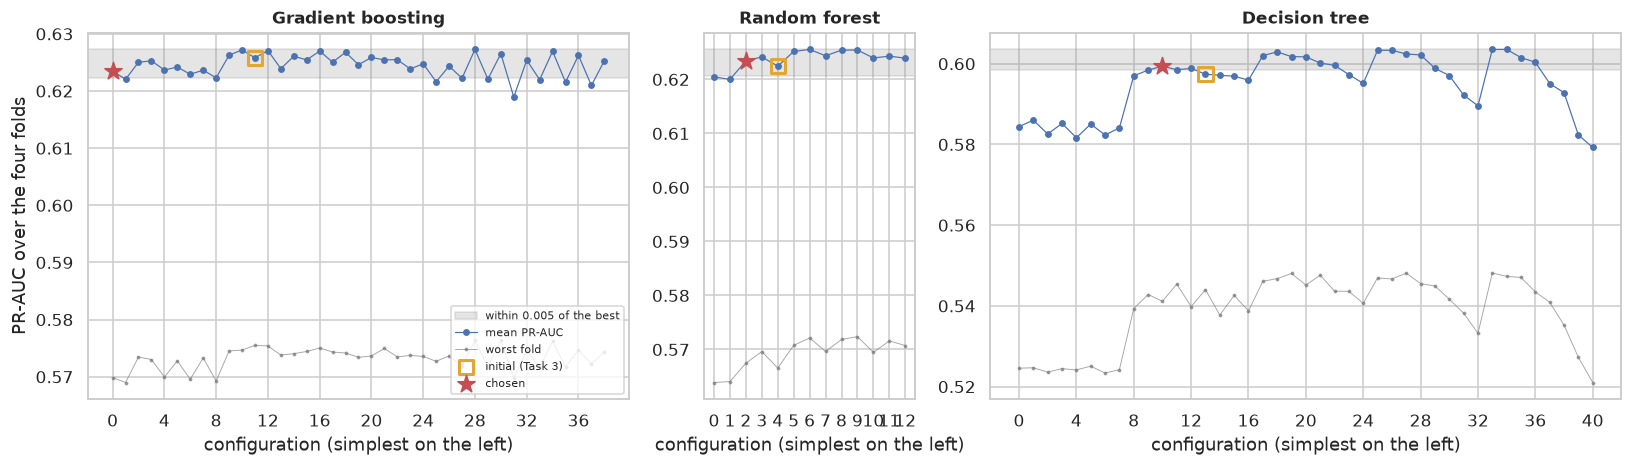

93 configurations searched in 35.4 min; extensions: {'Gradient boosting': {'max_depth': [3], 'min_samples_leaf': [400], 'max_iter': [100]}, 'Random forest': {'min_samples_leaf': [200]}, 'Decision tree': {'min_samples_leaf': [800]}}


In [15]:
SEARCHES = {"Gradient boosting": search_boosting, "Random forest": search_forest, "Decision tree": search_tree}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [36, 14, 42]})
for ax, (name, t) in zip(axes, SEARCHES.items()):
    x = np.arange(len(t))
    best = t["mean"].max()
    ax.axhspan(best - TOLERANCE, best, color=C_GREY, alpha=0.2, label=f"within {TOLERANCE} of the best")
    ax.plot(x, t["mean"], marker="o", ms=3.5, lw=0.8, color=C_NORMAL, label="mean PR-AUC")
    ax.plot(x, t["worst fold"], marker=".", ms=3, lw=0.6, color=C_GREY, alpha=0.7, label="worst fold")
    i_init, i_chosen = t.index.get_loc(INITIAL[name]), t.index.get_loc(CHOSEN[name])
    ax.scatter([i_init], [t["mean"].iloc[i_init]], s=90, marker="s", facecolor="none", edgecolor=C_ORANGE, lw=2, zorder=5, label="initial (Task 3)")
    ax.scatter([i_chosen], [t["mean"].iloc[i_chosen]], s=140, marker="*", color=C_ABN, zorder=6, label="chosen")
    ax.set_xticks(x[::4] if len(t) > 16 else x)
    ax.set_xlabel("configuration (simplest on the left)")
    ax.set_title(name)
axes[0].set_ylabel("PR-AUC over the four folds")
axes[0].legend(fontsize=7, loc="lower right")
fig.tight_layout()
savefig(fig, "04_search")

# One row per (model, configuration, fold), for prepared/task4_search.csv.
all_metrics = pd.concat(METRICS)
SEARCH_ROWS = []
for name, configs in SEARCH.items():
    for label, _, params in configs:
        sub = all_metrics[all_metrics["model"] == label].drop_duplicates("fold")
        assert len(sub) == 4
        for _, r in sub.iterrows():
            SEARCH_ROWS.append({"model": name, "configuration": label, **params, "fold": r["fold"], "PR-AUC": r["PR-AUC"], "ROC-AUC": r["ROC-AUC"],
                                "Brier": r["Brier"], "log-loss": r["log-loss"], "seconds": r["seconds"], "chosen": label == CHOSEN[name]})
search_rows = pd.DataFrame(SEARCH_ROWS)
assert (search_rows.groupby(["model", "configuration"]).size() == 4).all()
assert (search_rows[search_rows["chosen"]].groupby("model")["configuration"].nunique() == 1).all()
print(f"{search_rows['configuration'].nunique()} configurations searched in "
      f"{sum(SEARCH_SECONDS.values()) / 60:.1f} min; extensions: {EXTENDED}")

The figure summarises the 93 configurations, searched in 35.9 minutes. For gradient boosting and the random forest, 31 of 39 and 11 of 13
configurations fall inside the grey band of 0.005 below the best, so the hyperparameters in our ranges change the mean PR-AUC by less than
the noise we accept. The decision tree is the only model whose grid matters: the shallow trees on the left and the deep trees with small
leaves on the right are clearly lower. The worst fold (thin line) moves with the mean, so no configuration buys a better average at the cost
of a much worse quarter.

---
## 5. Optimised versus initial, and the final model

For each model we compare the configuration chosen by the search with its Task 3 configuration, fold by fold. Following the rule that Task 3
used for the ablation, we call an improvement meaningful when the mean PR-AUC gain is larger than the tolerance of 0.005, and stable when the
optimised configuration wins in at least 3 of the 4 folds. We adopt the optimised configuration only if its gain is both meaningful and stable;
otherwise the Task 3 configuration stays, which is a result in itself. With four dependent folds we compute no p-value (Task 2, Section 8).

The final model is then the kept configuration with the best mean PR-AUC. If another one is within the tolerance, the better worst fold
decides, because the protocol says a model should not be judged on its average alone, and then the lower cost.

In [16]:
VERDICTS, KEPT = [], {}
fold_cols = [f"fold {f['fold']}" for f in FOLDS]
for name in SEARCH:
    initial, optimised = INITIAL[name], CHOSEN[name]
    pr = metric_table([initial, optimised] if optimised != initial else [initial])
    roc = metric_table([initial, optimised] if optimised != initial else [initial], "ROC-AUC")
    brier = metric_table([initial, optimised] if optimised != initial else [initial], "Brier")
    diff, s = paired(pr.loc[optimised, fold_cols], pr.loc[initial, fold_cols])
    won = int((diff > 0).sum())
    meaningful, stable = bool(diff.mean() > TOLERANCE), bool(won >= 3)
    KEPT[name] = optimised if meaningful and stable else initial
    VERDICTS.append({"model": name, "initial": initial, "optimised": optimised, "mean gain": diff.mean(), "folds won": won,
                     "worst-fold gain": pr.loc[optimised, fold_cols].min() - pr.loc[initial, fold_cols].min(),
                     "ROC-AUC gain": roc.loc[optimised, "mean"] - roc.loc[initial, "mean"],
                     "Brier change": brier.loc[optimised, "mean"] - brier.loc[initial, "mean"],
                     "meaningful": meaningful, "stable": stable, "kept": KEPT[name]})
verdicts = pd.DataFrame(VERDICTS).set_index("model")
display(verdicts.style.format({"mean gain": "{:+.4f}", "worst-fold gain": "{:+.4f}", "ROC-AUC gain": "{:+.4f}", "Brier change": "{:+.4f}"}))
print("Per-fold PR-AUC, initial and optimised:")
display(metric_table(list(dict.fromkeys([l for v in VERDICTS for l in (v["initial"], v["optimised"])]))).style.format("{:.4f}"))

,initial,optimised,mean gain,folds won,worst-fold gain,ROC-AUC gain,Brier change,meaningful,stable,kept
model,,,,,,,,,,
Gradient boosting,"HGB depth=6, lr=0.1, 200 it, leaf=100","HGB depth=4, lr=0.1, 100 it, leaf=200",-0.0023,1,-0.0056,+0.0001,+0.0003,False,False,"HGB depth=6, lr=0.1, 200 it, leaf=100"
Random forest,"RF leaf=50, features=sqrt","RF leaf=100, features=9",+0.0010,4,+0.0009,+0.0004,-0.0002,False,True,"RF leaf=50, features=sqrt"
Decision tree,"DT depth=8, leaf=100, gini","DT depth=8, leaf=400, entropy",+0.0020,3,-0.0029,+0.0015,-0.0000,False,True,"DT depth=8, leaf=100, gini"


Per-fold PR-AUC, initial and optimised:


,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
"HGB depth=6, lr=0.1, 200 it, leaf=100",0.6176,0.5755,0.6497,0.6604,0.6258
"HGB depth=4, lr=0.1, 100 it, leaf=200",0.6185,0.5698,0.6470,0.6585,0.6235
"RF leaf=50, features=sqrt",0.6154,0.5666,0.6460,0.6619,0.6224
"RF leaf=100, features=9",0.6170,0.5675,0.6468,0.6624,0.6234
"DT depth=8, leaf=100, gini",0.5865,0.5440,0.6239,0.6352,0.5974
"DT depth=8, leaf=400, entropy",0.5923,0.5411,0.6264,0.6378,0.5994


In [17]:
weights = fold_table["validation sessions"].to_numpy()
all_metrics = pd.concat(METRICS)
rows = []
for name, label in KEPT.items():
    pr = metric_table([label]).loc[label, fold_cols]
    s = summarise_folds(pr.to_numpy(), weights)
    other = all_metrics[all_metrics["model"] == label].drop_duplicates("fold")[["ROC-AUC", "Brier", "log-loss", "seconds"]].mean()
    rows.append({"model": name, "configuration": label, "PR-AUC mean": s["mean (unweighted)"], "std": s["std across folds"],
                 "worst fold": s["worst fold"], "ROC-AUC": other["ROC-AUC"], "Brier": other["Brier"], "log-loss": other["log-loss"],
                 "seconds per fold": other["seconds"]})
for label in BASELINES:
    pr = metric_table([label]).loc[label, fold_cols]
    other = all_metrics[all_metrics["model"] == label][["ROC-AUC", "Brier", "log-loss"]].mean()
    rows.append({"model": label, "configuration": "", "PR-AUC mean": pr.mean(), "std": pr.std(ddof=1), "worst fold": pr.min(),
                 "ROC-AUC": other["ROC-AUC"], "Brier": other["Brier"], "log-loss": other["log-loss"], "seconds per fold": np.nan})
kept_table = pd.DataFrame(rows).set_index("model")

# Final model: best mean PR-AUC; within the tolerance, the better worst fold, then the lower cost.
models = kept_table.loc[list(KEPT)]
contenders = models[models["PR-AUC mean"] >= models["PR-AUC mean"].max() - TOLERANCE]
FINAL_MODEL = contenders.sort_values(["worst fold", "seconds per fold"], ascending=[False, True]).index[0]
FINAL_LABEL = KEPT[FINAL_MODEL]
kept_table["final"] = ["yes" if m == FINAL_MODEL else "" for m in kept_table.index]
display(kept_table.sort_values("PR-AUC mean", ascending=False).style.format(
    {"PR-AUC mean": "{:.4f}", "std": "{:.3f}", "worst fold": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.4f}", "log-loss": "{:.4f}",
     "seconds per fold": "{:.1f}"}, na_rep="—"))
d, s = paired(metric_table([FINAL_LABEL]).loc[FINAL_LABEL, fold_cols], metric_table([BASELINES[1]]).loc[BASELINES[1], fold_cols])
print(f"Final model: {FINAL_MODEL} ({FINAL_LABEL}); contenders within the tolerance: {list(contenders.index)}")
print(f"Gain over B1: {s['mean difference']:+.4f} on average, {s['folds won']} folds won")

log_decision("5", "Optimisation verdict",
             "; ".join(f"{v['model']}: {'optimised configuration adopted' if v['kept'] == v['optimised'] and v['optimised'] != v['initial'] else 'Task 3 configuration kept'}"
                       for v in VERDICTS) + ".",
             "; ".join(f"{v['model']} {v['optimised']} vs {v['initial']}: mean gain {v['mean gain']:+.4f}, {v['folds won']} of 4 folds won"
                       for v in VERDICTS) + f". Adopted only if gain > {TOLERANCE} and at least 3 of 4 folds won.")
log_decision("5", "Final model", f"{FINAL_MODEL}: {FINAL_LABEL}.",
             f"Mean PR-AUC {kept_table.loc[FINAL_MODEL, 'PR-AUC mean']:.4f}, worst fold {kept_table.loc[FINAL_MODEL, 'worst fold']:.3f}; "
             f"contenders within {TOLERANCE}: {', '.join(contenders.index)}; gain over B1 {s['mean difference']:+.4f} ({s['folds won']}).")

,configuration,PR-AUC mean,std,worst fold,ROC-AUC,Brier,log-loss,seconds per fold,final
model,,,,,,,,,
Gradient boosting,"HGB depth=6, lr=0.1, 200 it, leaf=100",0.6258,0.038,0.575,0.836,0.1020,0.3373,2.8,yes
Random forest,"RF leaf=50, features=sqrt",0.6224,0.042,0.567,0.835,0.1025,0.3391,12.3,
Decision tree,"DT depth=8, leaf=100, gini",0.5974,0.041,0.544,0.824,0.1046,0.3471,2.5,
B1 post failure rate (7 days),,0.5106,0.042,0.456,0.772,0.1176,0.3847,—,
B0 no skill,,0.1812,0.021,0.162,0.504,0.1478,0.4719,—,


Final model: Gradient boosting (HGB depth=6, lr=0.1, 200 it, leaf=100); contenders within the tolerance: ['Gradient boosting', 'Random forest']
Gain over B1: +0.1152 on average, 4 of 4 folds won


None of the three optimised configurations passes our rule, so each model keeps its Task 3 configuration. For gradient boosting, the
configuration chosen by the search is simpler (depth 4, 100 iterations) and slightly worse: −0.0023 on average, winning only 1 of the 4
folds. For the random forest, the chosen configuration wins all 4 folds, so the change is stable, but the mean gain of +0.0010 is far below
the tolerance. For the tree, the gain is +0.0020 with 3 folds won, but the worst fold drops by 0.0029. The ROC-AUC and the Brier score
barely move in any of the three.

The searches therefore confirm Task 3 rather than improve it. The one larger difference in the grids, the depth-16 tree at 0.0061 above the
Task 3 tree, needs twice the depth and is still 0.022 below gradient boosting, so it would not change the final choice.

The final model is gradient boosting with its Task 3 configuration (depth 6, learning rate 0.1, 200 iterations, leaves of at least 100
sessions). Its mean PR-AUC of 0.6258 is 0.0034 above the random forest, inside the tolerance, so the tie is broken by the worst fold: 0.575
for boosting against 0.567 for the forest. Boosting is also about four times faster to fit (3.1 against 12.0 seconds per fold). It beats B1
in all four folds, by +0.1152 on average.

---
## 6. Decision threshold

### 6.1 The criterion

A score becomes an alert only once a cut-off is fixed. The brief asks for one criterion, chosen from validation predictions. We use the
operational alert-rate constraint of the Task 2 protocol: the cut-off flags 10% of the sessions, so an operator inspects about 100 sessions
in every 1,000.

We have no data on the cost of a missed failure against the cost of an unnecessary inspection, nor on how many sessions the operator can
check. A cost-based cut-off would need a cost ratio that we would have to invent (the ratio of 10 to 1 in the evaluation lab belongs to its
churn example, not to charging faults), and the protocol does not use F1 to select anything because it weights precision and recall equally
without an operational reason. An alert budget is the one quantity an operator can set directly. Of the three budgets that the protocol
reports (5%, 10% and 20%), we take the middle one; the other two appear in Section 6.4 only as context for a smaller or larger capacity.

The cut-off is computed on the pooled out-of-fold predictions of the four folds: every development validation session receives a score from
the final configuration fitted on the training window of its own fold, so no score comes from a model that saw that session or anything
after it.

In [18]:
log_decision("6", "Threshold criterion",
             "Alert-rate constraint: the cut-off flags 10% of the pooled out-of-fold development predictions of the final model.",
             "Cost ratio and inspection capacity are unknown; the protocol excludes F1 from selection; 10% is the middle of the protocol's 5%, 10% and 20% budgets; "
             "each pooled score comes from a model that did not see that session.")

### 6.2 The cut-off and its stability across folds

In [19]:
OOF_Y = np.concatenate([df.loc[f["valid"], TARGET].to_numpy() for f in FOLDS])
OOF_P = np.concatenate([PREDS[(FINAL_LABEL, f["fold"])] for f in FOLDS])
OOF_FOLD = np.concatenate([np.full(len(f["valid"]), f["fold"]) for f in FOLDS])
assert len(OOF_P) == 235_472 == fold_table["validation sessions"].sum()          # one score per validation session

k = int(round(TARGET_ALERT_RATE * len(OOF_P)))
CUT_OFF = float(np.sort(OOF_P)[::-1][k - 1])                                      # k-th largest score; flag if score >= CUT_OFF
pooled_rate = (OOF_P >= CUT_OFF).mean()
print(f"Selected cut-off: {CUT_OFF:.4f} (flags {pooled_rate:.2%} of the {len(OOF_P):,} pooled out-of-fold predictions)")

PER_FOLD_CUT_OFFS = {int(f["fold"]): float(np.quantile(OOF_P[OOF_FOLD == f["fold"]], 1 - TARGET_ALERT_RATE)) for f in FOLDS}
rows = []
for f in FOLDS:
    m = OOF_FOLD == f["fold"]
    rows.append({"fold": f["fold"], "abnormal share": OOF_Y[m].mean(), "fold's own 10% cut-off": PER_FOLD_CUT_OFFS[f["fold"]],
                 **{k_: v for k_, v in operating_point(OOF_Y[m], OOF_P[m], CUT_OFF).items() if k_ != "cut-off"}})
per_fold_op = pd.DataFrame(rows).set_index("fold")
print(f"Pooled cut-off applied to each fold (the fold's own 90th percentile is shown for comparison):")
display(per_fold_op.style.format({**OP_FORMAT, "abnormal share": "{:.1%}", "fold's own 10% cut-off": "{:.4f}"}, na_rep="—"))

Selected cut-off: 0.4899 (flags 10.00% of the 235,472 pooled out-of-fold predictions)
Pooled cut-off applied to each fold (the fold's own 90th percentile is shown for comparison):


,abnormal share,fold's own 10% cut-off,precision,recall,F1,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
fold,,,,,,,,,
1,16.8%,0.4286,0.751,0.375,0.500,8.4%,63.2,21.0,105.2
2,15.8%,0.3892,0.713,0.347,0.467,7.7%,54.9,22.1,103.3
3,18.2%,0.5052,0.739,0.423,0.538,10.4%,77.2,27.2,105.1
4,21.1%,0.5668,0.745,0.430,0.545,12.2%,90.8,31.1,120.6


The cut-off that flags 10% of the 235,472 pooled out-of-fold predictions is 0.4899. Applied to each fold, it flags between 7.7% and 12.2% of
the sessions, and the alert rate follows the abnormal share of the quarter (15.8% in fold 2, 21.1% in fold 4). Each fold's own 10% cut-off
would range from 0.389 to 0.567. Precision, on the other hand, stays between 0.713 and 0.751 in every fold. A fixed cut-off keeps the
quality of an alert stable and lets the number of alerts rise and fall with the failure level, so an operator should expect more alerts in a
bad quarter rather than a constant 10%.

### 6.3 The default cut-off of 0.50 against the selected cut-off

The table compares the two cut-offs on the pooled predictions and in each fold. The figure follows the threshold exercise of the evaluation
lab: precision, recall and F1 of the pooled predictions for every cut-off between 0.01 and 0.99, with both cut-offs marked, and the share of
sessions that each cut-off flags.

In [20]:
OPERATING_POINTS = []
for scope, mask in [("pooled", np.ones(len(OOF_P), bool))] + [(f"fold {f['fold']}", OOF_FOLD == f["fold"]) for f in FOLDS]:
    for name, cut in [("default 0.50", 0.5), ("selected", CUT_OFF)]:
        OPERATING_POINTS.append({"name": name, "scope": scope, **operating_point(OOF_Y[mask], OOF_P[mask], cut)})
op_dev = pd.DataFrame(OPERATING_POINTS).set_index(["scope", "name"])
display(op_dev.style.format(OP_FORMAT, na_rep="—"))

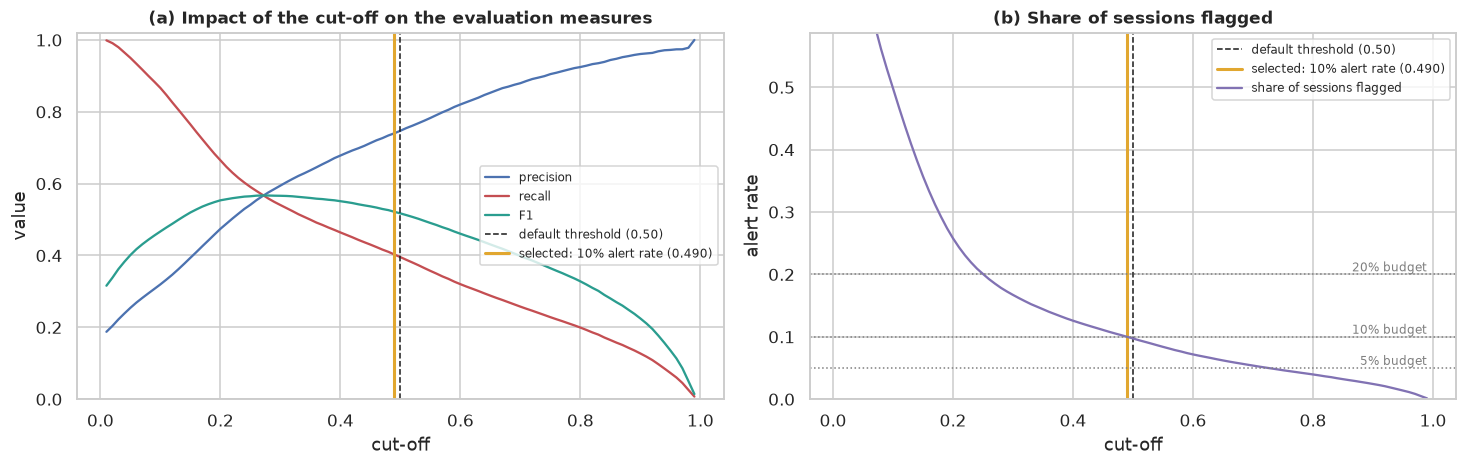

In [21]:
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
curve = pd.DataFrame([operating_point(OOF_Y, OOF_P, t) for t in grid])
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
axes[0].plot(grid, curve["precision"], color=C_NORMAL, label="precision")
axes[0].plot(grid, curve["recall"], color=C_ABN, label="recall")
axes[0].plot(grid, curve["F1"], color=C_GREEN, label="F1")
for ax in axes:
    ax.axvline(0.5, color="k", ls="--", lw=1, label="default threshold (0.50)")
    ax.axvline(CUT_OFF, color=C_ORANGE, lw=2, label=f"selected: 10% alert rate ({CUT_OFF:.3f})")
    ax.set_xlabel("cut-off")
axes[0].set_ylabel("value"); axes[0].set_ylim(0, 1.02)
axes[0].set_title("(a) Impact of the cut-off on the evaluation measures"); axes[0].legend(fontsize=8, loc="center right")
axes[1].plot(grid, curve["alert rate"], color=C_PURPLE, label="share of sessions flagged")
for q in ALERT_BUDGETS:
    axes[1].axhline(q, color=C_GREY, ls=":", lw=1)
    axes[1].text(0.99, q, f"{q:.0%} budget", ha="right", va="bottom", fontsize=8, color=C_GREY)
axes[1].set_ylabel("alert rate"); axes[1].set_ylim(0, max(0.5, curve["alert rate"].max() * 0.6))
axes[1].set_title("(b) Share of sessions flagged"); axes[1].legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "06_threshold")

The two cut-offs give almost the same operating point, because the 10% budget happens to fall just below 0.50. On the pooled predictions,
0.50 flags 9.7% of the sessions with a precision of 0.747 and a recall of 0.395; the selected 0.490 flags 10.0% with 0.740 and 0.403. Per
1,000 sessions the selected cut-off adds 1.3 correct alerts and 1.4 false ones, and misses 109.8 abnormal sessions instead of 111.1. Every
fold shows the same small shift.

The closeness is not a property of 0.50 in general. It holds because the scores of this model are close to probabilities (Section 7) and
about 10% of the sessions have a predicted risk above one half. The figure shows that F1 would peak at a much lower cut-off, around 0.3,
where the model flags well over 10% of the sessions; the protocol does not use F1 to choose, so we keep the budget. The difference from 0.50
is that our cut-off comes from a stated capacity and would stay meaningful for another model whose scores are not calibrated.

### 6.4 Operational consequences

To translate the cut-off into work for an operator, the table below gives the pooled measures at the three budgets of the protocol. The 10%
row is the selected operating point; the 5% and 20% rows show what a smaller or a larger inspection capacity would give with the same model.

In [22]:
rows = []
for q in ALERT_BUDGETS:
    cut = float(np.sort(OOF_P)[::-1][int(round(q * len(OOF_P))) - 1])
    rows.append({"budget": f"{q:.0%}" + (" (selected)" if q == TARGET_ALERT_RATE else ""), **operating_point(OOF_Y, OOF_P, cut)})
budgets_table = pd.DataFrame(rows).set_index("budget")
display(budgets_table.style.format(OP_FORMAT, na_rep="—"))
print(f"Abnormal sessions per 1,000 in the development quarters: {1000 * OOF_Y.mean():.1f}")
print(f"Cost ratio implied by the selected cut-off if the scores were calibrated probabilities: c = (1 - t) / t = {(1 - CUT_OFF) / CUT_OFF:.2f}")

,cut-off,precision,recall,F1,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
budget,,,,,,,,
5%,0.725,0.894,0.243,0.382,5.0%,44.7,5.3,139.1
10% (selected),0.490,0.740,0.403,0.522,10.0%,74.0,26.0,109.8
20%,0.251,0.542,0.590,0.565,20.0%,108.4,91.6,75.4


Abnormal sessions per 1,000 in the development quarters: 183.8
Cost ratio implied by the selected cut-off if the scores were calibrated probabilities: c = (1 - t) / t = 1.04


At the 10% budget an operator inspects 100 sessions in every 1,000: 74.0 of them are real failures and 26.0 are false alerts, and 109.8 of
the 183.8 abnormal sessions per 1,000 are still missed. The two other budgets show the trade-off. Going from 5% to 10% adds 29.3 correct
alerts for 20.7 more false ones, so the extra inspections still find more failures than they waste. Going from 10% to 20% adds 34.4 correct
alerts for 65.6 more false ones, about two wasted inspections for each extra failure found. Of the three budgets, 10% is the last one where
the extra alerts are more often right than wrong.

If the scores are read as calibrated probabilities, the cut-off of 0.490 corresponds to a cost ratio of 1.04, as if a missed failure cost
about the same as an unnecessary inspection. Task 2 argued that a missed failure costs more. If the operator agrees and has the capacity,
the 20% row shows what a larger budget would give; with the capacity unknown, we keep 10%.

---
## 7. Calibration check

A model is calibrated when, among the sessions that receive a score of about 0.3, about 30% are abnormal. The evaluation slides (MINDD-04)
note that trees and forests give class proportions that are sometimes scores rather than probabilities, so we check the final model
before reading its outputs as probabilities. We use the pooled out-of-fold predictions: a reliability curve over ten score bands with equal
numbers of sessions (mean predicted score against the observed abnormal share in each band), the Brier score, and, per fold, the mean
predicted score against the observed share. Calibration is not in the slides beyond this remark; we check it because the brief asks whether
it is needed for the chosen use.

,mean predicted,observed abnormal share,gap
score band (10% of sessions each),,,
1,0.013,0.015,0.002
2,0.025,0.025,0.000
3,0.039,0.044,0.005
4,0.058,0.066,0.008
5,0.084,0.093,0.010
6,0.116,0.126,0.010
7,0.153,0.161,0.008
8,0.208,0.223,0.015
9,0.347,0.344,-0.003


,mean predicted,observed abnormal share,Brier
fold,,,
1,0.158,0.168,0.097
2,0.158,0.158,0.097
3,0.179,0.182,0.100
4,0.204,0.211,0.114


Pooled Brier score 0.1032 (constant prior 0.1500); largest gap between predicted and observed in a band: 0.015


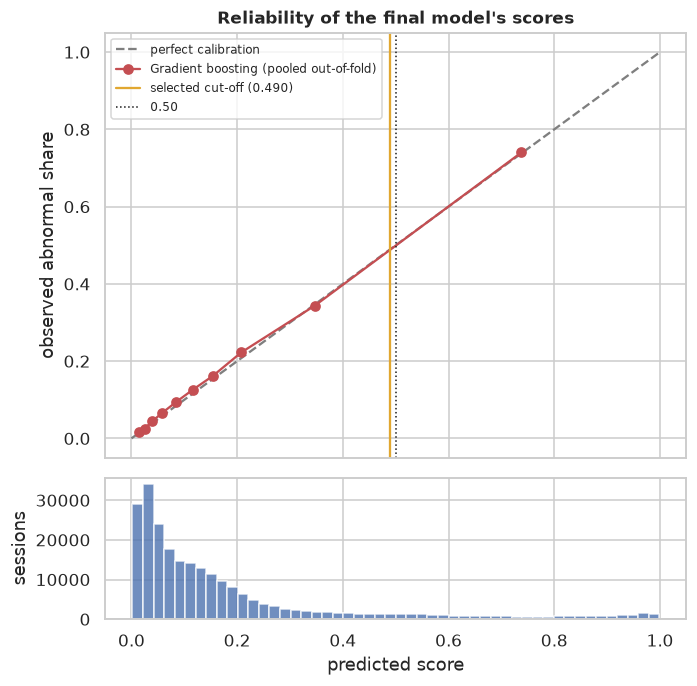

In [23]:
prob_true, prob_pred = calibration_curve(OOF_Y, OOF_P, n_bins=10, strategy="quantile")
brier_pooled = brier_score_loss(OOF_Y, OOF_P)
brier_prior = brier_score_loss(OOF_Y, np.full(len(OOF_Y), OOF_Y.mean()))
bands = pd.DataFrame({"mean predicted": prob_pred, "observed abnormal share": prob_true, "gap": prob_true - prob_pred})
bands.index = pd.RangeIndex(1, len(bands) + 1, name="score band (10% of sessions each)")
display(bands.style.format("{:.3f}"))
per_fold_cal = pd.DataFrame([{"fold": f["fold"], "mean predicted": OOF_P[OOF_FOLD == f["fold"]].mean(), "observed abnormal share": OOF_Y[OOF_FOLD == f["fold"]].mean(),
                              "Brier": brier_score_loss(OOF_Y[OOF_FOLD == f["fold"]], OOF_P[OOF_FOLD == f["fold"]])} for f in FOLDS]).set_index("fold")
display(per_fold_cal.style.format("{:.3f}"))
largest_gap = bands["gap"].abs().max()
print(f"Pooled Brier score {brier_pooled:.4f} (constant prior {brier_prior:.4f}); largest gap between predicted and observed in a band: {largest_gap:.3f}")

fig, axes = plt.subplots(2, 1, figsize=(6.5, 6.4), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
axes[0].plot([0, 1], [0, 1], color=C_GREY, ls="--", label="perfect calibration")
axes[0].plot(prob_pred, prob_true, marker="o", color=C_ABN, label=f"{FINAL_MODEL} (pooled out-of-fold)")
axes[0].axvline(CUT_OFF, color=C_ORANGE, lw=1.5, label=f"selected cut-off ({CUT_OFF:.3f})")
axes[0].axvline(0.5, color="k", ls=":", lw=1, label="0.50")
axes[0].set_ylabel("observed abnormal share"); axes[0].set_title("Reliability of the final model's scores"); axes[0].legend(fontsize=8)
axes[1].hist(OOF_P, bins=50, color=C_NORMAL, alpha=0.8)
axes[1].set_xlabel("predicted score"); axes[1].set_ylabel("sessions")
fig.tight_layout()
savefig(fig, "07_calibration")
CALIBRATION = {"Brier": float(brier_pooled), "Brier constant prior": float(brier_prior), "largest band gap": float(largest_gap),
               "bands": [{"mean predicted": float(a), "observed": float(b)} for a, b in zip(prob_pred, prob_true)],
               "per fold": per_fold_cal.reset_index().to_dict("records")}

The scores are close to calibrated. The pooled Brier score is 0.1032, against 0.1500 for a constant prediction of the training prior. In the
ten bands of equal size, the mean predicted score and the observed abnormal share differ by at most 0.015 (band 8: 0.208 predicted, 0.223
observed). The model slightly under-predicts in the middle bands (gaps of 0.005 to 0.015) and is accurate at both ends, including the top
band where the alerts are (0.738 against 0.740). Per fold, the mean score follows the abnormal share closely, with the largest gap in fold 1
(0.158 against 0.168).

We do not add a calibration step. The criterion uses the scores only to rank the sessions and fix an alert budget, and a calibration that
keeps the order of the scores would flag exactly the same sessions. Calibration would matter if the scores were shown to the operator as
risks or used with a cost-based cut-off; for those uses the gaps above, under 2 percentage points, are small enough to read the scores as
approximate probabilities.

In [24]:
CALIBRATION["decision"] = ("No calibrator is fitted: the 10% criterion uses the scores only as a ranking, which calibration would not change; "
                           f"the reliability check (Brier {brier_pooled:.4f}, largest band gap {largest_gap:.3f}) decides how far the scores can be read as probabilities.")
log_decision("7", "Calibration", "No calibrator; scores used as a ranking for the 10% alert budget.",
             f"Pooled out-of-fold Brier score {brier_pooled:.4f} against {brier_prior:.4f} for the constant prior; largest gap between mean predicted and observed "
             f"share over ten equal-frequency bands {largest_gap:.3f}; a monotone calibrator would not change which sessions are flagged.")

---
## 8. Freezing the final choices

Everything that the test evaluation needs is now fixed: the model and its configuration, the 27 features, the cut-off and the criterion
that produced it, and the calibration decision. We write them to `prepared/task4_frozen.json`, together with the development estimates
that the test result will be compared with. Section 9 reads the model, the features and the cut-off from this file, not from the variables
in memory, and nothing in this notebook changes them after the test period has been scored.

In [25]:
dev_point = op_dev.loc[("pooled", "selected")]
final_metrics = all_metrics[all_metrics["model"] == FINAL_LABEL].drop_duplicates("fold")
FROZEN_CHOICES = {
    "frozen_at": datetime.now().isoformat(timespec="seconds"),
    "model": FINAL_MODEL,
    "configuration": FINAL_LABEL,
    "hyperparameters": PARAMS[FINAL_LABEL],
    "features": SELECTED,
    "criterion": "alert rate 10% of pooled out-of-fold predictions",
    "alert_rate_target": TARGET_ALERT_RATE,
    "cut_off": CUT_OFF,
    "calibration": "none",
    "development_estimates": {"PR-AUC mean": float(final_metrics["PR-AUC"].mean()), "ROC-AUC": float(final_metrics["ROC-AUC"].mean()),
                              "Brier": float(final_metrics["Brier"].mean()), "log-loss": float(final_metrics["log-loss"].mean()),
                              "precision": float(dev_point["precision"]), "recall": float(dev_point["recall"]),
                              "F1": float(dev_point["F1"]), "alert rate": float(dev_point["alert rate"])},
}
(OUT_DIR / "task4_frozen.json").write_text(json.dumps(FROZEN_CHOICES, indent=2, default=float))
log_decision("8", "Frozen choices", f"{FINAL_MODEL} ({FINAL_LABEL}), 27 Task 3 features, cut-off {CUT_OFF:.4f}, no calibrator; written to prepared/task4_frozen.json.",
             f"Frozen at {FROZEN_CHOICES['frozen_at']}, before the test period is read; development estimates: mean PR-AUC "
             f"{FROZEN_CHOICES['development_estimates']['PR-AUC mean']:.4f}, precision {dev_point['precision']:.3f} and recall {dev_point['recall']:.3f} at the cut-off.")
N_DECISIONS_AT_FREEZE = len(DECISIONS)
print(json.dumps(FROZEN_CHOICES, indent=1, default=float))
assert df["start_time"].max() < TEST_START          # nothing so far has seen a test session

{
 "frozen_at": "2026-10-28T11:16:57",
 "model": "Gradient boosting",
 "configuration": "HGB depth=6, lr=0.1, 200 it, leaf=100",
 "hyperparameters": {
  "max_depth": 6,
  "learning_rate": 0.1,
  "max_iter": 200,
  "min_samples_leaf": 100
 },
 "features": [
  "hour",
  "dow",
  "location",
  "district",
  "temperature",
  "humidity",
  "precipitation",
  "rain_flag",
  "post_previous_sessions_1D",
  "post_previous_sessions_7D",
  "post_previous_sessions_30D",
  "post_previous_abnormal_rate_1D",
  "post_previous_abnormal_rate_7D",
  "post_previous_abnormal_rate_30D",
  "post_hours_since_previous_completed_session",
  "post_hours_since_previous_completed_abnormal",
  "is_new_user",
  "user_previous_sessions_30D",
  "user_previous_sessions_180D",
  "user_previous_sessions_730D",
  "user_previous_abnormal_rate_30D",
  "user_previous_abnormal_rate_180D",
  "user_previous_abnormal_rate_730D",
  "user_days_since_previous_completed_session",
  "user_days_since_previous_completed_abnormal",
  "u

---
## 9. Final evaluation on the test period

This section is the only one that reads the test period. It loads the frozen file, refits the frozen configuration on all development
sessions whose label was known before the test start (a session that started in September 2021 but ended on or after 1 October is purged,
as in the folds), reads the test sessions, and scores them once. B0 and B1 are scored on the same sessions. The cut-off is applied
unchanged. A guard makes a second scoring in the same kernel fail.

In [26]:
assert "TEST_SCORED" not in globals(), "the test period has already been scored in this kernel"
FROZEN = json.loads((OUT_DIR / "task4_frozen.json").read_text())
print(f"Frozen choices loaded (frozen at {FROZEN['frozen_at']}): {FROZEN['model']}, {FROZEN['configuration']}, cut-off {FROZEN['cut_off']:.4f}")

final_label, final_factory, _ = MAKERS[FROZEN["model"]](**FROZEN["hyperparameters"])
assert final_label == FROZEN["configuration"]
dev_train = df[df["end_time"] < TEST_START]                                           # purge: label known before the test start
assert dev_train["start_time"].min() >= BURN_IN_END and dev_train["end_time"].max() < TEST_START
print(f"Final training data: {len(dev_train):,} development sessions ({len(df) - len(dev_train):,} purged because they ended on or after {TEST_START.date()})")
started = time.time()
final_model = final_factory(FROZEN["features"]).fit(dev_train[FROZEN["features"]], dev_train[TARGET])
if isinstance(final_model.named_steps["clf"], HistGradientBoostingClassifier):
    assert not final_model.named_steps["clf"].do_early_stopping_
print(f"Final model refitted in {time.time() - started:.0f} s")

Frozen choices loaded (frozen at 2026-10-28T11:16:57): Gradient boosting, HGB depth=6, lr=0.1, 200 it, leaf=100, cut-off 0.4899
Final training data: 346,931 development sessions (48 purged because they ended on or after 2021-10-01)


Final model refitted in 5 s


In [27]:
assert "TEST_SCORED" not in globals(), "the test period has already been scored in this kernel"
test, test_counts = load_sessions("test")
assert len(test) == 80_081 and test["start_time"].min() >= TEST_START
print(f"Test period: {len(test):,} sessions ({test['start_time'].min().date()} to {test['start_time'].max().date()}), abnormal share {test[TARGET].mean():.2%}")

y_test = test[TARGET].to_numpy()
p_test = final_model.predict_proba(test[FROZEN["features"]])[:, 1]
TEST_SCORED = True

rng_test = np.random.default_rng(SEED)
prior = dev_train[TARGET].mean()
TEST_SCORES = {FROZEN["model"]: (p_test, p_test), "B0 no skill": (rng_test.random(len(y_test)), np.full(len(y_test), prior)),
               "B1 post failure rate (7 days)": (test["post_previous_abnormal_rate_7D"].to_numpy(),) * 2}
rng_boot = np.random.default_rng(SEED)
resamples = [rng_boot.integers(0, len(y_test), len(y_test)) for _ in range(100)]
rows = []
for name, (score, prob) in TEST_SCORES.items():
    m = evaluate_scores(y_test, score, prob, rng=np.random.default_rng(SEED))
    se = np.std([average_precision_score(y_test[i], score[i]) for i in resamples], ddof=1)
    rows.append({"model": name, "PR-AUC": m["PR-AUC"], "PR-AUC bootstrap SE": se, "lift": m["lift"], "ROC-AUC": m["ROC-AUC"],
                 "Brier": m["Brier"], "log-loss": m["log-loss"]})
test_table = pd.DataFrame(rows).set_index("model")

dev = {FROZEN["model"]: FROZEN["development_estimates"]}
for label in BASELINES:
    sub = all_metrics[all_metrics["model"] == label]
    dev[label] = {"PR-AUC mean": sub["PR-AUC"].mean(), "ROC-AUC": sub["ROC-AUC"].mean(), "Brier": sub["Brier"].mean(), "log-loss": sub["log-loss"].mean()}
test_table.insert(1, "development PR-AUC (mean of folds)", [dev[m]["PR-AUC mean"] for m in test_table.index])
test_table["development ROC-AUC"] = [dev[m]["ROC-AUC"] for m in test_table.index]
display(test_table.style.format({"PR-AUC": "{:.4f}", "PR-AUC bootstrap SE": "{:.4f}", "development PR-AUC (mean of folds)": "{:.4f}", "lift": "{:.2f}",
                                 "ROC-AUC": "{:.3f}", "development ROC-AUC": "{:.3f}", "Brier": "{:.4f}", "log-loss": "{:.4f}"}))

test_points = []
for name, cut in [("default 0.50", 0.5), ("selected", FROZEN["cut_off"])]:
    test_points.append({"name": name, "scope": "test", **operating_point(y_test, p_test, cut)})
OPERATING_POINTS.extend(test_points)
op_compare = pd.DataFrame(test_points + [{**r, "scope": "development (pooled)"} for r in OPERATING_POINTS
                                         if r["scope"] == "pooled"]).set_index(["scope", "name"])
display(op_compare.style.format(OP_FORMAT, na_rep="—"))
observed_rate = float((p_test >= FROZEN["cut_off"]).mean())
print(f"Observed test alert rate at the frozen cut-off: {observed_rate:.2%} (target {FROZEN['alert_rate_target']:.0%})")
TEST_RESULT = {"sessions": int(len(test)), "abnormal share": float(y_test.mean()), "observed alert rate": observed_rate,
               "models": test_table.reset_index().drop(columns=["development PR-AUC (mean of folds)", "development ROC-AUC"]).to_dict("records")}

Test period: 80,081 sessions (2021-10-01 to 2021-12-31), abnormal share 17.59%


,PR-AUC,development PR-AUC (mean of folds),PR-AUC bootstrap SE,lift,ROC-AUC,Brier,log-loss,development ROC-AUC
model,,,,,,,,
Gradient boosting,0.5324,0.6258,0.0047,3.03,0.794,0.1131,0.3697,0.836
B0 no skill,0.1782,0.1812,0.0019,1.01,0.505,0.1451,0.4655,0.504
B1 post failure rate (7 days),0.3809,0.5106,0.0044,2.17,0.723,0.1293,0.4166,0.772


Observed test alert rate at the frozen cut-off: 7.43% (target 10%)


In [28]:
final_dev = metric_table([FINAL_LABEL]).loc[FINAL_LABEL, fold_cols]
b1_dev = metric_table([BASELINES[1]]).loc[BASELINES[1], fold_cols]
trend = summarise_folds(final_dev.to_numpy(), weights)["trend per fold"]
y4, p4 = OOF_Y[OOF_FOLD == 4], OOF_P[OOF_FOLD == 4]
rng_boot4 = np.random.default_rng(SEED)
se4 = np.std([average_precision_score(y4[i], p4[i]) for i in (rng_boot4.integers(0, len(y4), len(y4)) for _ in range(100))], ddof=1)
gap = pd.DataFrame({"abnormal share": list(fold_table["validation abnormal share"]) + [y_test.mean()],
                    "final model PR-AUC": list(final_dev) + [test_table.loc[FROZEN["model"], "PR-AUC"]],
                    "B1 PR-AUC": list(b1_dev) + [test_table.loc[BASELINES[1], "PR-AUC"]]},
                   index=[f"fold {f['fold']} ({f['lo'].date()})" for f in FOLDS] + [f"test ({TEST_START.date()})"])
gap["gain over B1"] = gap["final model PR-AUC"] - gap["B1 PR-AUC"]
gap["lift"] = gap["final model PR-AUC"] / gap["abnormal share"]
display(gap.style.format({"abnormal share": "{:.1%}", "final model PR-AUC": "{:.4f}", "B1 PR-AUC": "{:.4f}", "gain over B1": "{:+.4f}", "lift": "{:.2f}"}))
print(f"Development trend of the final model: {trend:+.4f} PR-AUC per fold | fold 4: {final_dev.iloc[-1]:.4f} (bootstrap SE {se4:.4f}) | "
      f"test: {test_table.loc[FROZEN['model'], 'PR-AUC']:.4f} (bootstrap SE {test_table.loc[FROZEN['model'], 'PR-AUC bootstrap SE']:.4f})")

t_final, t_b1 = test_table.loc[FROZEN["model"]], test_table.loc[BASELINES[1]]
log_decision("9", "Test result", "Reported as observed; no model, feature or cut-off is changed after this point.",
             f"Test PR-AUC {t_final['PR-AUC']:.4f} (bootstrap SE {t_final['PR-AUC bootstrap SE']:.4f}) against {t_b1['PR-AUC']:.4f} for B1 "
             f"(gain {t_final['PR-AUC'] - t_b1['PR-AUC']:+.4f}) and {test_table.loc[BASELINES[0], 'PR-AUC']:.4f} for B0; development mean {FROZEN['development_estimates']['PR-AUC mean']:.4f}; "
             f"observed alert rate {observed_rate:.2%} at the frozen cut-off {FROZEN['cut_off']:.4f}.")
assert len(DECISIONS) == N_DECISIONS_AT_FREEZE + 1

,abnormal share,final model PR-AUC,B1 PR-AUC,gain over B1,lift
fold 1 (2020-10-01),16.8%,0.6176,0.4991,+0.1185,3.67
fold 2 (2021-01-01),15.8%,0.5755,0.4562,+0.1193,3.64
fold 3 (2021-04-01),18.2%,0.6497,0.5466,+0.1031,3.56
fold 4 (2021-07-01),21.1%,0.6604,0.5403,+0.1201,3.12
test (2021-10-01),17.6%,0.5324,0.3809,+0.1516,3.03


Development trend of the final model: +0.0203 PR-AUC per fold | fold 4: 0.6604 (bootstrap SE 0.0036) | test: 0.5324 (bootstrap SE 0.0047)


The final model was refitted on 346,931 development sessions; 48 sessions that started before 1 October but ended on or after it were
purged, as in the folds. The test period has 80,081 sessions with an abnormal share of 17.59%.

The final model reaches a test PR-AUC of 0.5324 (bootstrap standard error 0.0047), against 0.3809 for B1 and 0.1782 for B0. It still ranks
the sessions three times better than no skill (lift 3.03) and beats B1 by 0.1516, more than its average margin of 0.1152 on the development
folds. In absolute terms, however, the test score is 0.093 below the development mean of 0.6258 and 0.128 below fold 4, the most recent
quarter (0.6604). That gap is about 27 times the bootstrap standard error, so it is a real change in the last quarter of 2021 and not
sampling noise. It also breaks the upward trend of the development folds (+0.020 per fold). B1 falls by even more, from 0.540 in fold 4 to
0.381. This suggests that what weakened is the signal of recent post failures itself: in this quarter a recent failure at a post predicts
the next failure less well than before. ROC-AUC (0.794 against 0.836) and the Brier score (0.1131 against 0.1020) tell the same story.

At the frozen cut-off of 0.490 the model flags 7.43% of the test sessions instead of 10%. Its alerts are less precise than on development
(0.677 against 0.740) and catch fewer failures (recall 0.286 against 0.403): per 1,000 sessions, 50.3 correct alerts, 24.0 false alerts and
125.6 missed abnormal sessions. A smaller alert rate at a fixed cut-off was expected from Section 6.2, where the rate followed the abnormal
share, but 7.4% is lower than the development folds with a similar share (fold 3: 18.2% abnormal, 10.4% flagged), because fewer test
sessions receive a score above the cut-off. The default 0.50 gives almost the same result again (7.1% flagged, precision 0.686, recall
0.278). We report these numbers as observed and change nothing after them.

---
## 10. Interpretation of the final model

We measure how much the final model relies on each group of information with permutation importance on held-out data. For each fold, the
frozen configuration is fitted on the training window and scored on its validation quarter; then the columns of one feature group are
shuffled together across the sessions of that quarter and the drop in PR-AUC is recorded (5 shuffles per group, with a fixed seed). A large
drop means that the fitted model depends on that group to rank the sessions. We do the same for each single variable (3 shuffles) to name the
leading ones. Permutation importance is not in the slides; we use it because it works for any of the three candidate models and measures,
on sessions that the model did not see, how much it uses a group. It complements the Task 3 ablation, which retrained the model without the
group. The groups are those of the ablation restricted to the 27 features: calendar, location (station and district), weather, post
history, user history and concurrency. This section reads no test session, and it comes after the test evaluation so that nothing it shows
could influence a frozen choice.

In [29]:
INTERP_GROUPS = {"calendar": GROUPS["calendar"], "location": [c for c in GROUPS["location"] if c in SELECTED], "weather": GROUPS["weather"],
                 "post history": GROUPS["post_history"], "user history": GROUPS["user_history"], "concurrency": GROUPS["concurrency"]}
assert sorted(c for cols in INTERP_GROUPS.values() for c in cols) == sorted(SELECTED)


def permutation_drop(model, X, y, columns, repeats, rng):
    """PR-AUC drops when the rows of `columns` are shuffled jointly (one permutation per repeat, applied to every column of the group).
    Shuffling a correlated group at once avoids the windows standing in for each other."""
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    drops = []
    for _ in range(repeats):
        Xp = X.copy()
        perm = rng.permutation(len(X))
        for c in columns:
            Xp[c] = X[c].to_numpy()[perm]
        drops.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
    return drops


rng_perm = np.random.default_rng(SEED)
group_rows, var_rows = [], []
t0 = time.time()
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    model = final_factory(FROZEN["features"]).fit(tr[FROZEN["features"]], tr[TARGET])
    X, y = va[FROZEN["features"]], va[TARGET].to_numpy()
    for group, cols in INTERP_GROUPS.items():
        for drop in permutation_drop(model, X, y, cols, 5, rng_perm):
            group_rows.append({"fold": f["fold"], "group": group, "drop": drop})
    for col in FROZEN["features"]:
        for drop in permutation_drop(model, X, y, [col], 3, rng_perm):
            var_rows.append({"fold": f["fold"], "variable": col, "drop": drop})
print(f"permutation importance on the four validation quarters computed in {time.time() - t0:.0f} s")

group_imp = pd.DataFrame(group_rows)
by_fold = group_imp.groupby(["group", "fold"])["drop"].mean().unstack()
by_fold.columns = [f"fold {c}" for c in by_fold.columns]
group_table = pd.DataFrame({"PR-AUC drop": group_imp.groupby("group")["drop"].mean(), "std": group_imp.groupby("group")["drop"].std(ddof=1),
                            "features": {g: len(c) for g, c in INTERP_GROUPS.items()}}).join(by_fold).sort_values("PR-AUC drop", ascending=False)
var_imp = pd.DataFrame(var_rows)
var_table = pd.DataFrame({"PR-AUC drop": var_imp.groupby("variable")["drop"].mean(), "std": var_imp.groupby("variable")["drop"].std(ddof=1),
                          "group": {c: g for g, cols in INTERP_GROUPS.items() for c in cols}}).sort_values("PR-AUC drop", ascending=False)
display(group_table.style.format({c: "{:.4f}" for c in group_table.columns if c != "features"}))
display(var_table.head(10).style.format({"PR-AUC drop": "{:.4f}", "std": "{:.4f}"}))

permutation importance on the four validation quarters computed in 145 s


,PR-AUC drop,std,features,fold 1,fold 2,fold 3,fold 4
post history,0.3657,0.0249,8,0.3617,0.3278,0.3880,0.3851
user history,0.0974,0.0204,10,0.1084,0.1202,0.0941,0.0669
location,0.0121,0.0014,2,0.0138,0.0111,0.0113,0.0121
calendar,0.0016,0.0008,2,0.0018,0.0027,0.0010,0.0009
concurrency,0.0011,0.0004,1,0.0017,0.0008,0.0009,0.0008
weather,0.0007,0.0010,4,-0.0003,0.0022,0.0006,0.0001


,PR-AUC drop,std,group
post_previous_abnormal_rate_1D,0.1959,0.0384,post history
post_hours_since_previous_completed_abnormal,0.0383,0.0116,post history
post_previous_abnormal_rate_7D,0.0258,0.0096,post history
user_days_since_previous_completed_abnormal,0.0243,0.0072,user history
post_previous_abnormal_rate_30D,0.0119,0.0028,post history
location,0.0118,0.0010,location
user_previous_abnormal_rate_730D,0.0093,0.0030,user history
user_previous_abnormal_rate_30D,0.0067,0.0019,user history
post_previous_sessions_1D,0.0047,0.0029,post history
post_hours_since_previous_completed_session,0.0046,0.0016,post history


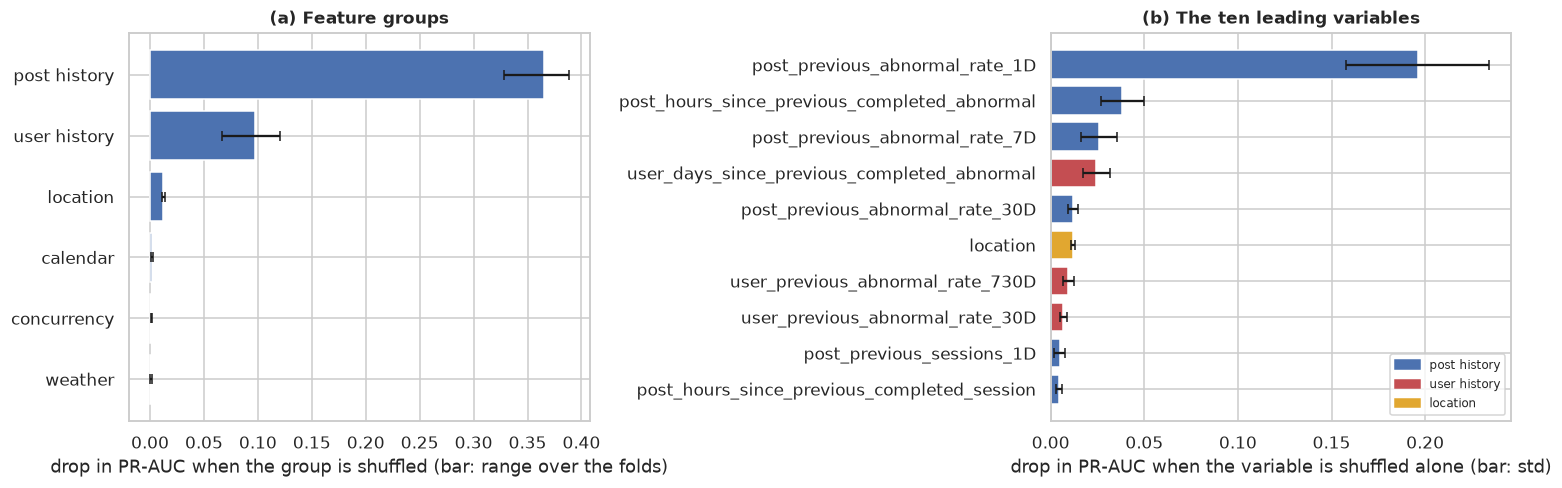

,permutation drop (final model),Task 3 ablation gain
post history,0.3657,0.2938
user history,0.0974,0.0270
location,0.0121,—
calendar,0.0016,—
concurrency,0.0011,—
weather,0.0007,—


Task 3 ablation gains: post history = S3 - S2; user history (with concurrency) = selected set - selected set without user history.


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
g = group_table.iloc[::-1]
fold_part = g[[c for c in g.columns if c.startswith("fold")]]
axes[0].barh(g.index, g["PR-AUC drop"], color=C_NORMAL, xerr=[g["PR-AUC drop"] - fold_part.min(axis=1), fold_part.max(axis=1) - g["PR-AUC drop"]], capsize=3)
axes[0].set_xlabel("drop in PR-AUC when the group is shuffled (bar: range over the folds)")
axes[0].set_title("(a) Feature groups")
v = var_table.head(10).iloc[::-1]
palette = dict(zip(INTERP_GROUPS, [C_GREY, C_ORANGE, C_GREEN, C_NORMAL, C_ABN, C_PURPLE]))
axes[1].barh(v.index, v["PR-AUC drop"], xerr=v["std"], color=[palette[x] for x in v["group"]], capsize=3)
axes[1].set_xlabel("drop in PR-AUC when the variable is shuffled alone (bar: std)")
axes[1].set_title("(b) The ten leading variables")
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[x]) for x in dict.fromkeys(v["group"][::-1])], labels=list(dict.fromkeys(v["group"][::-1])),
               fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "10_importance")

ablation = TASK3["ablation"]
ablation_gain = {"post history": ablation["S3 + post history"]["PR-AUC mean"] - ablation["S2 + tariff"]["PR-AUC mean"],
                 "user history": ablation["S4 without post_id and tariff (selected)"]["PR-AUC mean"] - ablation["selected without user history"]["PR-AUC mean"]}
compare = pd.DataFrame({"permutation drop (final model)": group_table["PR-AUC drop"],
                        "Task 3 ablation gain": pd.Series(ablation_gain)}).loc[group_table.index]
display(compare.style.format("{:.4f}", na_rep="—"))
print("Task 3 ablation gains: post history = S3 - S2; user history (with concurrency) = selected set - selected set without user history.")
IMPORTANCE = {"groups": [{"name": g, "PR-AUC drop": float(r["PR-AUC drop"]), "std": float(r["std"]),
                          "per fold": {c: float(r[c]) for c in by_fold.columns}} for g, r in group_table.iterrows()],
              "variables": [{"name": v_, "PR-AUC drop": float(r["PR-AUC drop"]), "std": float(r["std"])} for v_, r in var_table.iterrows()]}
log_decision("10", "Interpretation method",
             "Group and single-variable permutation importance (drop in PR-AUC) on the four validation quarters, with fold-specific fits of the frozen configuration.",
             "Model-agnostic and measured on unseen sessions; groups are shuffled jointly because the history windows are correlated; descriptive only, no frozen choice changes.")
assert len(DECISIONS) == N_DECISIONS_AT_FREEZE + 2            # the extra entry describes the method; it changes no model, feature or cut-off

The model depends mostly on the post history. Shuffling its eight variables together lowers the PR-AUC by 0.366 on average, between 0.328
and 0.388 depending on the fold. User history comes second with 0.097, and its importance shrinks over time (0.108 in fold 1, 0.067 in fold
4). Location costs 0.012, and the calendar, concurrency and weather groups less than 0.002 each, so the model barely uses them. The leading
single variable is the abnormal rate of the post over the last day (0.196), well ahead of the time since the post's last abnormal session
(0.038) and the 7-day rate used by B1 (0.026). The most recent window carries the most information once the model has it.

The ranking of the groups agrees with the Task 3 ablation, but the sizes differ. Removing the post history and retraining cost 0.294 in Task
3, and removing user history cost 0.027, against permutation drops of 0.366 and 0.097 here. The two methods answer different questions.
Permutation measures how much this fitted model uses a group; the ablation measures what is lost when the model is retrained without it, and
a retrained model can partly replace user history with post history. User history is therefore used a lot by the model but adds only a
little that the other groups cannot recover.

Permutation importance has three limits in our setting. Correlated variables share their importance: when one window is shuffled alone, the
other windows still carry part of its information, so single-variable drops understate a variable's role. Shuffling whole groups avoids this
for the group ranking. It measures how the model uses a variable, not whether that variable causes failures. And it is computed on the four
validation quarters, not on the test period, so it describes the model as developed, before the change observed in Section 9.

---
## 11. Conclusions and limitations

### 11.1 Conclusions

The search over 93 configurations confirmed the Task 3 configurations instead of improving them. For gradient boosting and the random
forest, almost every configuration lies within our tolerance of 0.005 of the best, and for the decision tree the only real lever is the
minimum leaf size. The final model is gradient boosting with its Task 3 configuration, chosen over the random forest on the worst fold.

We chose the cut-off from a 10% alert budget on the pooled out-of-fold predictions. It is 0.490, almost the default 0.50, because the scores
are close to calibrated, so no calibration step is needed for an alert budget. On development, this cut-off gives 74 correct alerts, 26
false alerts and 110 missed failures per 1,000 sessions, and of the three budgets of the protocol it is the last one where extra alerts are
more often right than wrong.

On the test period the model scores a PR-AUC of 0.532, against 0.381 for B1 and 0.178 for B0. It keeps a clear and even larger advantage
over the simple rule, but both lose much of their development level, and with the frozen cut-off the model flags 7.4% of the sessions with a
precision of 0.677. The model relies mostly on recent post failures and then on the user's history, and the weakening of the post-failure
signal in the last quarter of 2021, visible in B1 as well, is the most likely reason for the drop.

### 11.2 Limitations

The search, the tie rule and the final choice all used the same four folds, so the development estimate of 0.626 is slightly optimistic; the
test result is the unbiased check, and it is one quarter of 80,081 sessions from a single period, so it measures this quarter and not a
long-run average. The drop from development to test shows that the relation between recent post failures and the next failure can change, so
the development estimates may not hold in later periods; we did not investigate the cause on the test data, because the test is only scored,
never explored. The gradient-boosting search still chose the smallest number of iterations after one widening, so the boosting range was not
fully explored on that side, although every configuration near it lies within the tolerance. The 10% budget is a choice, not a measured
inspection capacity, and at 0.490 it implies treating a missed failure as costing about the same as a false alert, which is lower than the
cost argued in Task 2. The calibration check covers the development quarters only. Permutation importance shares importance among correlated
variables, measures use rather than cause, and describes the model on the validation quarters, not the test period.

---
## 12. Saved files and decision log

The results are saved so that the report and any later work can use them without repeating the search: the search results, the per-fold
metrics of the initial and chosen configurations and of the baselines, the frozen choices (already written in Section 8), the summary of the
operating points, the calibration check, the test result and the importance, and the decision log.

In [31]:
for (label, fold), p in PREDS.items():
    assert len(p) == fold_table.loc[fold, "validation sessions"], (label, fold)       # one prediction per validation session
assert SELECTED == TASK3["selected_features"] == FROZEN["features"]
assert FROZEN["configuration"] == FINAL_LABEL and FROZEN["cut_off"] == CUT_OFF and FROZEN["model"] == FINAL_MODEL
assert TEST_SCORED and sum(r["scope"] == "test" for r in OPERATING_POINTS) == 2                # the test period was scored once
assert df["start_time"].max() < TEST_START                                                       # the development frame never held a test row

search_rows.to_csv(OUT_DIR / "task4_search.csv", index=False)
fold_labels = BASELINES + list(dict.fromkeys(list(INITIAL.values()) + list(CHOSEN.values())))
fold_metrics = pd.concat(METRICS)
fold_metrics = fold_metrics[fold_metrics["model"].isin(fold_labels)].drop_duplicates(["model", "fold"]).reset_index(drop=True)
assert all(fold_metrics.loc[fold_metrics["fold"] == f["fold"], "validation sessions"].eq(len(f["valid"])).all() for f in FOLDS)
fold_metrics.to_csv(OUT_DIR / "task4_fold_metrics.csv", index=False)

results = {
    "protocol": "prepared/task2_protocol.json (folds, metrics, alert budgets); test rows dropped right after reading until Section 9, "
                "read again only after prepared/task4_frozen.json was written, and scored once",
    "tolerance": TOLERANCE,
    "selected_models": SELECTED_MODELS,
    "search_spaces": {name: {"grid": GRID_VALUES[name], "order": ORDER[name], "extended": EXTENDED[name]} for name in GRID_VALUES},
    "chosen_configurations": CHOSEN,
    "verdicts": [{k: v for k, v in r.items()} for r in VERDICTS],
    "final_model": FINAL_LABEL,
    "operating_points": [{"name": r["name"], "cut_off": r["cut-off"], "scope": r["scope"], "precision": r["precision"], "recall": r["recall"],
                          "F1": r["F1"], "alert rate": r["alert rate"], "correct per 1,000": r["correct per 1,000"],
                          "false per 1,000": r["false per 1,000"], "missed per 1,000": r["missed per 1,000"]} for r in OPERATING_POINTS],
    "per_fold_cut_offs": PER_FOLD_CUT_OFFS,
    "calibration": CALIBRATION,
    "test": TEST_RESULT,
    "importance": IMPORTANCE,
}
clean = json.loads(json.dumps(results, default=float).replace("NaN", "null"))
(OUT_DIR / "task4_results.json").write_text(json.dumps(clean, indent=2, ensure_ascii=False))
decision_log = pd.DataFrame(DECISIONS)
decision_log.to_csv(OUT_DIR / "task4_decision_log.csv", index=False)
print("Saved:", *(OUT_DIR / n for n in ["task4_frozen.json", "task4_search.csv", "task4_fold_metrics.csv", "task4_results.json", "task4_decision_log.csv"]),
      "| figures in", FIG_DIR)
display(decision_log.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Saved: prepared/task4_frozen.json prepared/task4_search.csv prepared/task4_fold_metrics.csv prepared/task4_results.json prepared/task4_decision_log.csv | figures in prepared/figures_task4


section,topic,decision,evidence
3,Models chosen for optimisation,"Gradient boosting, random forest and decision tree (boosting, bagging with random features, single tree). Stacking, logistic regression and Naive Bayes are not searched.","Task 3 mean PR-AUC 0.626, 0.622 and 0.597; boosting and the forest differ by 0.003 (inside the tolerance); the tree is the best individual model. Stacking is 0.015 behind boosting; LR gave the same PR-AUC for C = 0.01 and C = 1; NB smoothing does not address its independence assumption."
4,Search procedure,"Exhaustive grid per model (36, 12 and 40 configurations) on the four development folds; objective = unweighted mean PR-AUC; simplest configuration within 0.005 of the best; a range is widened once if the choice lies on its edge.","Same folds, runner and selection rule as Task 3, so initial and optimised configurations are chosen the same way; no random split and no early stopping; the test period plays the outer role of a nested search."
4,Gradient boosting configuration,"HGB depth=4, lr=0.1, 100 it, leaf=200.","Mean PR-AUC 0.6235, worst fold 0.570, rank 29 of 39; edge rule: {'max_depth': [3], 'min_samples_leaf': [400], 'max_iter': [100]}."
4,Random forest configuration,"RF leaf=100, features=9.","Mean PR-AUC 0.6234, worst fold 0.567, rank 10 of 13; edge rule: {'min_samples_leaf': [200]}."
4,Decision tree configuration,"DT depth=8, leaf=400, entropy.","Mean PR-AUC 0.5994, worst fold 0.541, rank 15 of 41; edge rule: {'min_samples_leaf': [800]}."
5,Optimisation verdict,Gradient boosting: Task 3 configuration kept; Random forest: Task 3 configuration kept; Decision tree: Task 3 configuration kept.,"Gradient boosting HGB depth=4, lr=0.1, 100 it, leaf=200 vs HGB depth=6, lr=0.1, 200 it, leaf=100: mean gain -0.0023, 1 of 4 folds won; Random forest RF leaf=100, features=9 vs RF leaf=50, features=sqrt: mean gain +0.0010, 4 of 4 folds won; Decision tree DT depth=8, leaf=400, entropy vs DT depth=8, leaf=100, gini: mean gain +0.0020, 3 of 4 folds won. Adopted only if gain > 0.005 and at least 3 of 4 folds won."
5,Final model,"Gradient boosting: HGB depth=6, lr=0.1, 200 it, leaf=100.","Mean PR-AUC 0.6258, worst fold 0.575; contenders within 0.005: Gradient boosting, Random forest; gain over B1 +0.1152 (4 of 4)."
6,Threshold criterion,Alert-rate constraint: the cut-off flags 10% of the pooled out-of-fold development predictions of the final model.,"Cost ratio and inspection capacity are unknown; the protocol excludes F1 from selection; 10% is the middle of the protocol's 5%, 10% and 20% budgets; each pooled score comes from a model that did not see that session."
7,Calibration,No calibrator; scores used as a ranking for the 10% alert budget.,Pooled out-of-fold Brier score 0.1032 against 0.1500 for the constant prior; largest gap between mean predicted and observed share over ten equal-frequency bands 0.015; a monotone calibrator would not change which sessions are flagged.
8,Frozen choices,"Gradient boosting (HGB depth=6, lr=0.1, 200 it, leaf=100), 27 Task 3 features, cut-off 0.4899, no calibrator; written to prepared/task4_frozen.json.","Frozen at 2026-10-28T11:16:57, before the test period is read; development estimates: mean PR-AUC 0.6258, precision 0.740 and recall 0.403 at the cut-off."


---
## 13. Final comparison and model description

The final submission asks for one table that compares the candidate, baseline and final models, and for one description of the final
preprocessing, feature set, hyperparameters and threshold. This section gathers both from the files that Tasks 3 and 4 have already saved,
so every number in it can be traced to an earlier section. It fits no model and reads no test row: the only test numbers are the ones
Section 9 produced for the final model and the two baselines, and no other candidate is scored on the test period.

In [32]:
# Everything is read back from the saved files, so this section can be checked on its own and cannot change an earlier result.
T3 = json.loads((OUT_DIR / "task3_results.json").read_text())
T4 = json.loads((OUT_DIR / "task4_results.json").read_text())
FROZEN_FILE = json.loads((OUT_DIR / "task4_frozen.json").read_text())
t4_folds = pd.read_csv(OUT_DIR / "task4_fold_metrics.csv")
B0_LABEL, B1_LABEL = "B0 no skill", "B1 post failure rate (7 days)"
t3_rows = {r["model"] if r["model"].startswith("B") else r["model"].split(" (")[0]: r for r in T3["comparison"]}   # by model name, not label
test_pr = {m["model"]: m["PR-AUC"] for m in T4["test"]["models"]}                 # the single test evaluation of Section 9
b1_folds = t4_folds[t4_folds["model"] == B1_LABEL].set_index("fold")["PR-AUC"]
assert abs(b1_folds.mean() - t3_rows[B1_LABEL]["PR-AUC mean"]) < 1e-9             # Tasks 3 and 4 share the same baseline


def task3_row(block, name, configuration):
    r = t3_rows[name]
    return {"block": block, "model": name, "configuration": configuration, "dev PR-AUC mean": r["PR-AUC mean"], "worst fold": r["worst fold"],
            "gain over B1": r["gain over B1"], "folds won vs B1": r["folds won vs B1"], "test PR-AUC": test_pr.get(name, np.nan), "is final": False}


def task4_row(block, name, label):
    folds = t4_folds[t4_folds["model"] == label].set_index("fold")["PR-AUC"]
    assert len(folds) == 4, label
    return {"block": block, "model": name, "configuration": label, "dev PR-AUC mean": folds.mean(), "worst fold": folds.min(),
            "gain over B1": folds.mean() - b1_folds.mean(), "folds won vs B1": f"{int((folds > b1_folds).sum())} of 4",
            "test PR-AUC": test_pr[name] if block == "final" else np.nan, "is final": block == "final"}


CANDIDATES = ["Logistic regression", "Naive Bayes", "Decision tree", "Random forest", "Gradient boosting", "Stacking"]
rows = [task3_row("baseline", B0_LABEL, "random score"), task3_row("baseline", B1_LABEL, "share of abnormal sessions at the post, last 7 days")]
rows += [task3_row("candidate", name, T3["selected_configurations"][name]) for name in CANDIDATES]
rows += [task4_row("optimised", v["model"], v["optimised"]) for v in T4["verdicts"]]
rows += [task4_row("final", FROZEN_FILE["model"], FROZEN_FILE["configuration"])]
final_comparison = pd.DataFrame(rows)
for name in CANDIDATES:                                                            # candidates were never scored on the test period
    final_comparison.loc[final_comparison["model"].eq(name) & final_comparison["block"].eq("candidate"), "test PR-AUC"] = np.nan

final_row = final_comparison[final_comparison["is final"]].iloc[0]
assert len(final_comparison) == 12
assert final_comparison["block"].value_counts().to_dict() == {"candidate": 6, "optimised": 3, "baseline": 2, "final": 1}
assert final_comparison["test PR-AUC"].notna().sum() == 3
assert set(final_comparison.loc[final_comparison["test PR-AUC"].notna(), "model"]) == {FROZEN_FILE["model"], B0_LABEL, B1_LABEL}
assert final_row["dev PR-AUC mean"] == FROZEN_FILE["development_estimates"]["PR-AUC mean"]
assert abs(final_row["dev PR-AUC mean"] - t3_rows["Gradient boosting"]["PR-AUC mean"]) < 1e-5     # the Task 3 and Task 4 runs differ by about 2e-6
assert final_row["worst fold"] == t3_rows["Gradient boosting"]["worst fold"]
assert final_row["test PR-AUC"] == T4["test"]["models"][0]["PR-AUC"] and T4["test"]["models"][0]["model"] == FROZEN_FILE["model"]
assert globals().get("TEST_SCORED", True)                                          # in the full run, the test was scored in Section 9

final_comparison.to_csv(OUT_DIR / "final_comparison.csv", index=False)
print(f"B1 mean development PR-AUC {b1_folds.mean():.3f}; test PR-AUC only for {FROZEN_FILE['model']}, B0 and B1")
display(final_comparison.drop(columns="is final").set_index(["block", "model"]).style
        .format({"dev PR-AUC mean": "{:.3f}", "worst fold": "{:.3f}", "gain over B1": "{:+.3f}", "test PR-AUC": "{:.3f}"}, na_rep="—")
        .apply(lambda r: ["font-weight: bold" if r.name[0] == "final" else ""] * len(r), axis=1))

B1 mean development PR-AUC 0.511; test PR-AUC only for Gradient boosting, B0 and B1


In [33]:
import sklearn

feature_groups = {group: [f for f in features if f in FROZEN_FILE["features"]] for group, features in GROUPS.items()}
feature_groups = {group: features for group, features in feature_groups.items() if features}    # tariff and post_id were dropped in Task 3
categorical = [f for f in FROZEN_FILE["features"] if f in FEATURE_GROUPS["categorical"]]
dev = FROZEN_FILE["development_estimates"]
final_model = {
    "data": {"development": f"sessions starting from {BURN_IN_END.date()} (end of the burn-in) and before {TEST_START.date()}",
             "folds": "four expanding-window folds with a purge gap (Task 2 protocol), used for every choice",
             "final training": f"all development sessions that ended before {TEST_START.date()}, so every label was known before the test",
             "test": f"sessions starting from {TEST_START.date()}, scored once with the frozen choices"},
    "target": {"positive": PROTOCOL["problem"]["positive_class"], "negative": PROTOCOL["problem"]["negative_class"],
               "prediction moment": PROTOCOL["problem"]["prediction_moment"]},
    "preprocessing": {"categories": f"{', '.join(categorical)}: ordinal codes learned on the training window; an unseen category is treated as missing",
                      "numeric features": "used as they are: no scaling and no log transform, since the trees only use the order of the values",
                      "missing values": "kept as missing; the model sends them to the better side of each split, so nothing is imputed",
                      "class imbalance": "no resampling and no class weights",
                      "fitted on": "every learned step is fitted on the training window only (learned-operations ledger, Task 1)"},
    "feature_groups": feature_groups,
    "hyperparameters": FROZEN_FILE["hyperparameters"],
    "fixed_settings": {"early_stopping": False, "random_state": SEED, "categorical_features": categorical,
                       "other settings": f"scikit-learn {sklearn.__version__} defaults"},
    "threshold": {"criterion": FROZEN_FILE["criterion"], "cut_off": FROZEN_FILE["cut_off"], "alert rate": dev["alert rate"],
                  "precision": dev["precision"], "recall": dev["recall"]},
    "calibration": {"decision": FROZEN_FILE["calibration"], "reason": T4["calibration"]["decision"]},
    "decided_in": {"data": "report Sections 3.1 and 4.5", "target": "report Section 1.1", "preprocessing": "report Section 3.3",
                   "feature_groups": "report Section 5.1", "hyperparameters": "report Sections 6.1 and 6.2",
                   "threshold": "report Section 6.3", "calibration": "report Section 6.4"},
}

assert sorted(sum(feature_groups.values(), [])) == sorted(FROZEN_FILE["features"]) and len(FROZEN_FILE["features"]) == 27
assert final_model["hyperparameters"] == FROZEN_FILE["hyperparameters"]
assert final_model["threshold"]["cut_off"] == FROZEN_FILE["cut_off"] and final_model["calibration"]["decision"] == FROZEN_FILE["calibration"]
(OUT_DIR / "final_model.json").write_text(json.dumps(final_model, indent=2, ensure_ascii=False, default=float))

summary = {"model": f"{FROZEN_FILE['model']} ({FROZEN_FILE['configuration']})",
           "features": "; ".join(f"{group} ({len(features)})" for group, features in feature_groups.items()) + f" = {len(FROZEN_FILE['features'])}",
           "hyperparameters": ", ".join(f"{k} = {v}" for k, v in FROZEN_FILE["hyperparameters"].items()) + ", no early stopping, seed 42",
           "preprocessing": f"ordinal codes for {' and '.join(categorical)} (fitted on the training window); numeric features and missing values unchanged",
           "threshold": f"{FROZEN_FILE['criterion']}: cut-off {FROZEN_FILE['cut_off']:.3f} "
                        f"(development precision {dev['precision']:.3f}, recall {dev['recall']:.3f}, alert rate {dev['alert rate']:.1%})",
           "calibration": final_model["calibration"]["decision"]}
display(pd.DataFrame.from_dict(summary, orient="index", columns=["final choice"]))

,final choice
model,"Gradient boosting (HGB depth=6, lr=0.1, 200 it, leaf=100)"
features,calendar (2); location (2); weather (4); post_history (8); user_history (10); concurrency (1) = 27
hyperparameters,"max_depth = 6, learning_rate = 0.1, max_iter = 200, min_samples_leaf = 100, no early stopping, seed 42"
preprocessing,ordinal codes for location and district (fitted on the training window); numeric features and missing values unchanged
threshold,"alert rate 10% of pooled out-of-fold predictions: cut-off 0.490 (development precision 0.740, recall 0.403, alert rate 10.0%)"
calibration,none


Gradient boosting leads the six Task 3 candidates with a mean PR-AUC of 0.626 and
beats B1 in all four folds, but the random forest is only 0.003 behind, inside our tolerance of 0.005, which is why Section 5 chose
between them on the worst fold (0.575 against 0.567). The three configurations found by the searches of Section 4 stay within 0.003 of
their Task 3 versions and none passed the rule of Section 5, so they are listed but not kept. The final row is the Task 3 configuration
refitted in this notebook, and its development numbers equal the Task 3 row. Only three rows have a test score, the ones Section 9
scored: 0.532 for the final model, against 0.381 for B1 and 0.178 for B0.

The description restates the choices frozen in Section 8 in a readable form, and the assertions check that its features,
hyperparameters, cut-off and calibration decision are the ones in `prepared/task4_frozen.json`. Chapter 7 of the report is built from
these two files.